# Single-Cell Dissection of Glucocorticoid Response Heterogeneity: Identifying Transcriptional Programs Associated With Hormone Responsiveness.

- How transcriptional profiles change
across dexamethasone exposure times.
- Which genes and pathways show variable expression between individual cells.
-Whether cells at the same time point display different transcriptional states.
-Whether single-cell findings agree with treatment-associated signals in bulk RNA-seq.


 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


 Install pinned analysis dependencies

In [ ]:
%pip install -q "pandas==2.2.3" "numpy==2.1.3" "anndata==0.11.4" "scanpy==1.11.5" "h5py==3.14.0" "numba==0.61.2" "zarr<3"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.3/211.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 7.0 MB/s eta 0:00:00


 Import libraries

In [ ]:
import os
import gzip
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import requests
from scipy import sparse

print("Libraries imported successfully.")
print("Scanpy:", sc.__version__)
print("Pandas:", pd.__version__)

Libraries imported successfully.
Scanpy: 1.11.5
Pandas: 2.2.3


/tmp/ipykernel_1449/596079877.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


Downloading and inspecting GSE141834

In [ ]:
!pip -q install GEOparse

import GEOparse

gse = GEOparse.get_GEO(
    geo="GSE141834",
    destdir="/content/geo_metadata"
)

print("Dataset:", gse.name)
print("Title:", gse.metadata.get("title"))
print("Summary:", gse.metadata.get("summary"))
print("Number of samples:", len(gse.gsms))

for gsm_id, gsm in gse.gsms.items():
    print("\nSample:", gsm_id)
    print("Title:", gsm.metadata.get("title"))
    print("Characteristics:", gsm.metadata.get("characteristics_ch1"))
    print("Supplementary files:", gsm.metadata.get("supplementary_file", []))

16-Oct-2026 22:10:29 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE141nnn/GSE141834/soft/GSE141834_family.soft.gz to /content/geo_metadata/GSE141834_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE141nnn/GSE141834/soft/GSE141834_family.soft.gz to /content/geo_metadata/GSE141834_family.soft.gz
100%|██████████| 5.51k/5.51k [00:00<00:00, 38.9kB/s]
16-Oct-2026 22:10:30 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
16-Oct-2026 22:10:30 DEBUG downloader - Moving /tmp/tmp5016gv6m to /content/geo_metadata/GSE141834_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp5016gv6m to /content/geo_metadata/GSE141834_family.soft.gz
16-Oct-2026 22:10:30 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE141nnn/GSE141834/soft/GSE141834_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE141nnn/GSE141834/soft/GSE141834_family.soft.gz
16-Oct-2026 2

Dataset: GSE141834
Title: ['Transcriptional Heterogeneity within the Glucocorticoid Response']
Summary: ['Steroid hormone receptors such as the Glucocorticoid Receptor (GR) mediate the transcriptional response to hormones and are frequently targeted in the treatment of human diseases. Experiments using bulk populations of cells have provided a detailed picture of the global transcriptional hormone response but are unable to interrogate cell-to-cell transcriptional heterogeneity. To examine the glucocorticoid response in individual cells, we performed single cell RNA sequencing (scRNAseq). The transcriptional response to hormone was robustly detected in individual cells and scRNAseq provided additional statistical power to identify over 100 GR-regulated genes that were not detected in bulk RNAseq. scRNAseq also revealed a large degree of cell-to-cell variability in the hormone response. On average, individual hormone-treated cells showed a response at only 30% of the total set of GR tar

Request the GEO record as text

In [ ]:
import requests

gse_id = "GSE141834"

url = (
    f"https://www.ncbi.nlm.nih.gov/geo/query/"
    f"acc.cgi?acc={gse_id}&targ=self&form=text&view=full"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

geo_text = response.text

print(geo_text[:15000])

^SERIES = GSE141834
!Series_title = Transcriptional Heterogeneity within the Glucocorticoid Response
!Series_geo_accession = GSE141834
!Series_status = Public on Mar 26 2020
!Series_submission_date = Dec 11 2019
!Series_last_update_date = Mar 29 2020
!Series_pubmed_id = 32170217
!Series_web_link = https://www.nature.com/articles/s42003-020-0837-0
!Series_summary = Steroid hormone receptors such as the Glucocorticoid Receptor (GR) mediate the transcriptional response to hormones and are frequently targeted in the treatment of human diseases. Experiments using bulk populations of cells have provided a detailed picture of the global transcriptional hormone response but are unable to interrogate cell-to-cell transcriptional heterogeneity. To examine the glucocorticoid response in individual cells, we performed single cell RNA sequencing (scRNAseq). The transcriptional response to hormone was robustly detected in individual cells and scRNAseq provided additional statistical power to identif

Downloading the counts matrix

In [ ]:
import os
import requests

# Temporary Colab storage
DATA_DIR = "/content/glucocorticoid_project"
os.makedirs(DATA_DIR, exist_ok=True)

# Raw single-cell count matrix
url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE141nnn/GSE141834/suppl/"
    "GSE141834_scRNAseq_rawCounts.txt.gz"
)

file_path = os.path.join(
    DATA_DIR,
    "GSE141834_scRNAseq_rawCounts.txt.gz"
)

if os.path.exists(file_path):
    print("File already exists. Skipping download.")
else:
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    with open(file_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Download complete.")

print(f"File size: {os.path.getsize(file_path) / 1e6:.2f} MB")
print("Location:", file_path)

Download complete.
File size: 13.44 MB
Location: /content/glucocorticoid_project/GSE141834_scRNAseq_rawCounts.txt.gz


###Inspecting metadata to preview the compressed file
Reads only the first few lines of the gzip-compressed file to inspect its format before loading the full
matrix. This helps identify whether the file contains headers, cell identifiers, and gene-level counts in the
expected layout

In [ ]:
import gzip
import itertools

with gzip.open(file_path, "rt") as f:
    for line in itertools.islice(f, 6):
        print(line[:500])

Dex.00.2_AGGTTATCGCCTATATAC	Dex.00.2_CTATTACTATTAGTCCTA	Dex.00.2_CAAGTCATCCGGGGACGA	Dex.00.2_ACCTTCTAATAGTGCTAA	Dex.00.2_TCGCCTAAAGAACATAGA	Dex.00.2_GAGGCCACAAGGACAAGG	Dex.00.2_GGATTGCTGTGGGCTTGT	Dex.00.2_CGTTATCTGTGGCTGTGG	Dex.00.2_TCGGGAAGTAAACAAGTC	Dex.00.2_GTACAGGGTAGGGAGGCC	Dex.00.2_CCGATGTGAGACGCTTGT	Dex.00.2_TTAAGAAACAGCTTAAGA	Dex.00.2_GCTTGTTGTTCGTTAAGA	Dex.00.2_AAGCCACTGTGGATAGCG	Dex.00.2_GCGAATACCCAATTCTTG	Dex.00.2_TTGGATGGACGAGTGGTG	Dex.00.2_ACCCAACAGACTTTGCTC	Dex.00.2_GACTCGTTCGCAACT
CTSH	0	0	1	0	2	0	1	0	0	0	0	1	1	0	0	0	2	0	1	0	1	1	1	0	0	0	1	0	0	0	1	1	0	1	1	1	1	5	0	0	0	0	1	1	1	1	1	0	0	0	2	1	2	0	2	0	1	0	0	0	1	0	0	1	1	0	0	0	0	0	0	0	2	0	0	1	0	0	0	1	0	1	0	0	1	1	1	0	0	1	1	1	0	0	2	3	0	0	0	0	1	0	0	0	0	1	0	0	1	0	2	1	2	0	1	1	0	0	0	0	0	2	0	0	0	1	0	0	0	0	1	0	0	0	1	1	1	0	1	0	3	0	1	2	0	1	1	1	0	1	1	1	0	1	0	3	0	0	1	0	1	0	0	1	2	1	2	1	0	0	0	1	1	1	1	2	0	0	0	0	1	2	0	1	0	0	2	0	0	1	1	0	0	0	1	1	0	1	0	0	0	0	1	1	2	1	0	0	0	0	0	1	0	2	0	0	1	0	0	1	4	0	0	2	5	3	1	0	0	0	1	3	0	0	1	0	0	0	0	1	2	0	1	1	1	1	1	

### Load the count matrix with Pandas
Loads the expression matrix into pandas and prepares the relevant libraries. The source matrix is
organized as genes by cells; later, AnnData is constructed in the standard cells-by-genes orientation

In [ ]:
import pandas as pd
import scanpy as sc
import numpy as np
from scipy.sparse import csr_matrix

# Path to downloaded count matrix
file_path = "/content/glucocorticoid_project/GSE141834_scRNAseq_rawCounts.txt.gz"

# Load genes as rows and cells as columns
counts = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    index_col=0
)

print("Matrix shape:", counts.shape)
print("\nFirst 5 genes:")
print(counts.iloc[:5, :5])
print("\nFirst 10 cell IDs:")
print(counts.columns[:10].tolist())

Matrix shape: (32049, 2400)

First 5 genes:
            Dex.00.2_AGGTTATCGCCTATATAC  Dex.00.2_CTATTACTATTAGTCCTA  \
CTSH                                  0                            0   
SFXN4                                 1                            0   
AC127537.3                            0                            0   
DCAF8L1                               0                            0   
RBM45                                 0                            0   

            Dex.00.2_CAAGTCATCCGGGGACGA  Dex.00.2_ACCTTCTAATAGTGCTAA  \
CTSH                                  1                            0   
SFXN4                                 0                            1   
AC127537.3                            0                            0   
DCAF8L1                               0                            0   
RBM45                                 1                            0   

            Dex.00.2_TCGCCTAAAGAACATAGA  
CTSH                                  2  
SFXN4 

### Inspect cell-ID prefixes
Extracts the prefix from each cell identifier and counts how many cells belong to each prefix. These
prefixes are used to infer sample-level groups and later map cells to treatment time points.

In [ ]:
cell_ids = counts.columns.astype(str)

prefixes = pd.Series(
    [cell_id.split("_")[0] for cell_id in cell_ids]
)

print("Unique cell-ID prefixes:")
print(prefixes.value_counts().to_string())

print("\nNumber of unique prefixes:", prefixes.nunique())

Unique cell-ID prefixes:
Dex.00.2    400
Dex.01.2    400
Dex.02.2    400
Dex.18.2    400
Dex.08.2    211
Dex.04.2    207
Dex.04.1    193
Dex.08.1    189

Number of unique prefixes: 8


### Validate raw count values
Checks the data type, missing values, negative values, and whether the expression values are integers.
These checks help confirm that the matrix behaves like a raw count matrix before normalization.

In [ ]:
print("Data type:", counts.dtypes.iloc[0])
print("Missing values:", counts.isna().sum().sum())
print("Negative values:", (counts < 0).any().any())
print("Non-integer values:", ((counts % 1) != 0).to_numpy().any())

Data type: int64
Missing values: 0
Negative values: False
Non-integer values: False


### Count cells by sample prefix
Counts how many cell columns are associated with each inferred sample prefix. This describes the
structure of the dataset and helps identify imbalances across prefixes

In [ ]:
# Count cells associated with each prefix
cell_ids = counts.columns.astype(str)

prefixes = pd.Series(
    [cell_id.split("_")[0] for cell_id in cell_ids],
    name="sample_prefix"
)

group_counts = prefixes.value_counts().sort_index()

print("Cells per prefix:")
print(group_counts)

print("\nTotal cells:", group_counts.sum())

Cells per prefix:
sample_prefix
Dex.00.2    400
Dex.01.2    400
Dex.02.2    400
Dex.04.1    193
Dex.04.2    207
Dex.08.1    189
Dex.08.2    211
Dex.18.2    400
Name: count, dtype: int64

Total cells: 2400


### Build a sample-prefix summary
Creates a compact table of cell counts by prefix. This summary is useful for documenting the composition
of the dataset before quality control and time-point mapping

In [ ]:
import pandas as pd

sample_summary = (
    pd.DataFrame({"cell_id": counts.columns.astype(str)})
    .assign(prefix=lambda df: df["cell_id"].str.split("_").str[0])
    .groupby("prefix")
    .size()
    .reset_index(name="n_cells")
)

sample_summary["time_label"] = (
    sample_summary["prefix"].str.extract(r"Dex\.(\d+)")
)

sample_summary["replicate_label"] = (
    sample_summary["prefix"].str.extract(r"\.(\d+)$")
)

print(sample_summary.to_string(index=False))

  prefix  n_cells time_label replicate_label
Dex.00.2      400         00               2
Dex.01.2      400         01               2
Dex.02.2      400         02               2
Dex.04.1      193         04               1
Dex.04.2      207         04               2
Dex.08.1      189         08               1
Dex.08.2      211         08               2
Dex.18.2      400         18               2


### Calculate per-cell quality-control metrics

Computes detected genes and total counts for every cell, then assembles the metrics into a QC table.
These measurements help identify cells with unusually low library size or few detected genes.

In [ ]:
import numpy as np
import pandas as pd

# Number of detected genes per cell
genes_per_cell = (counts > 0).sum(axis=0)

# Total counts per cell
counts_per_cell = counts.sum(axis=0)

qc = pd.DataFrame({
    "cell_id": counts.columns,
    "prefix": [cell.split("_")[0] for cell in counts.columns],
    "total_counts": counts_per_cell.values,
    "detected_genes": genes_per_cell.values
})

print("Detected genes per cell:")
print(qc["detected_genes"].describe())

print("\nTotal counts per cell:")
print(qc["total_counts"].describe())

print("\nQC summary by prefix:")
print(
    qc.groupby("prefix")[["total_counts", "detected_genes"]]
      .median()
      .round(0)
)

Detected genes per cell:
count     2400.000000
mean      6415.015833
std       1298.649715
min       2918.000000
25%       5548.500000
50%       6521.000000
75%       7305.250000
max      10502.000000
Name: detected_genes, dtype: float64

Total counts per cell:
count      2400.000000
mean      29447.745417
std       13595.163340
min        7730.000000
25%       19983.250000
50%       27075.500000
75%       36265.500000
max      105172.000000
Name: total_counts, dtype: float64

QC summary by prefix:
          total_counts  detected_genes
prefix                                
Dex.00.2       25102.0          6181.0
Dex.01.2       26260.0          6510.0
Dex.02.2       28450.0          6698.0
Dex.04.1       26447.0          6499.0
Dex.04.2       27498.0          6694.0
Dex.08.1       27076.0          6532.0
Dex.08.2       27203.0          6545.0
Dex.18.2       28588.0          6612.0


### Calculate mitochondrial percentages
Identifies gene names beginning with
MT- and calculates the fraction of each cell's counts attributable to
mitochondrial genes. Elevated mitochondrial percentages can indicate stressed or low-quality cells,
although thresholds should be interpreted in context.

In [ ]:
# Identify mitochondrial genes
gene_names = counts.index.astype(str)

mito_mask = gene_names.str.upper().str.startswith("MT-")

print("Mitochondrial genes identified:", mito_mask.sum())
print("Examples:", gene_names[mito_mask][:15].tolist())

# Calculate mitochondrial counts per cell
mito_counts = counts.loc[mito_mask].sum(axis=0)
total_counts = counts.sum(axis=0)

pct_mito = (mito_counts / total_counts) * 100

# Add to QC table
qc["pct_mito"] = pct_mito.values

print("\nMitochondrial percentage summary:")
print(qc["pct_mito"].describe())

print("\nMedian mitochondrial percentage by prefix:")
print(qc.groupby("prefix")["pct_mito"].median().round(2))

Mitochondrial genes identified: 31
Examples: ['MT-CO2', 'MT-TP', 'MT-TI', 'MT-TL1', 'MT-ND3', 'MT-TD', 'MT-TG', 'MT-TE', 'MT-CO3', 'MT-RNR1', 'MT-ATP6', 'MT-ATP8', 'MT-CYB', 'MT-TT', 'MT-ND4L']

Mitochondrial percentage summary:
count    2400.000000
mean        0.623736
std         0.855965
min         0.008761
25%         0.151655
50%         0.323669
75%         0.673965
max         4.955428
Name: pct_mito, dtype: float64

Median mitochondrial percentage by prefix:
prefix
Dex.00.2    0.22
Dex.01.2    0.25
Dex.02.2    0.31
Dex.04.1    0.55
Dex.04.2    0.42
Dex.08.1    0.64
Dex.08.2    0.53
Dex.18.2    0.25
Name: pct_mito, dtype: float64


### Plot quality-control distributions
Visualizes total counts, detected genes, and mitochondrial percentage across cells. The plots provide a
visual check of the distributions before choosing or applying cell-filtering thresholds.

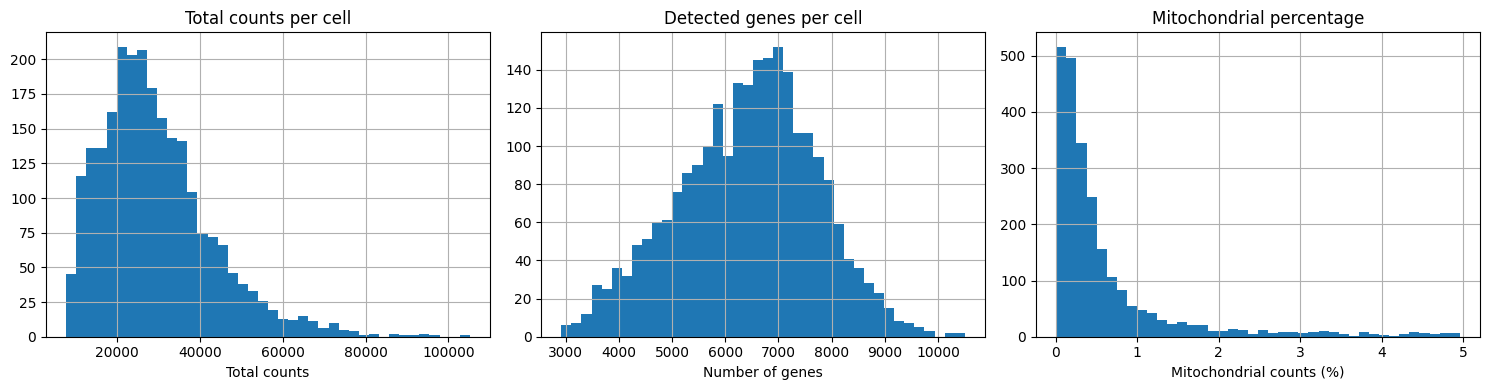

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

qc["total_counts"].hist(bins=40, ax=axes[0])
axes[0].set_title("Total counts per cell")
axes[0].set_xlabel("Total counts")

qc["detected_genes"].hist(bins=40, ax=axes[1])
axes[1].set_title("Detected genes per cell")
axes[1].set_xlabel("Number of genes")

qc["pct_mito"].hist(bins=40, ax=axes[2])
axes[2].set_title("Mitochondrial percentage")
axes[2].set_xlabel("Mitochondrial counts (%)")

plt.tight_layout()
plt.show()

###Create the AnnData object
Converts the genes-by-cells matrix into a cells-by-genes sparse AnnData object and attaches cell-level
metadata, including sample prefixes and QC measurements. Sparse storage reduces memory use for a
mostly zero single-cell matrix.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Convert genes × cells into cells × genes
adata = sc.AnnData(
    X=csr_matrix(counts.T.to_numpy(dtype=np.float32))
)

# Assign cell and gene identifiers
adata.obs_names = counts.columns.astype(str)
adata.var_names = counts.index.astype(str)

# Add QC metrics
adata.obs["sample_prefix"] = [
    cell.split("_")[0] for cell in adata.obs_names
]

adata.obs["total_counts"] = qc["total_counts"].to_numpy()
adata.obs["detected_genes"] = qc["detected_genes"].to_numpy()
adata.obs["pct_mito"] = qc["pct_mito"].to_numpy()

# Preserve the original counts
adata.layers["counts"] = adata.X.copy()

print(adata)
print("\nMetadata preview:")
print(adata.obs.head())

AnnData object with n_obs × n_vars = 2400 × 32049
    obs: 'sample_prefix', 'total_counts', 'detected_genes', 'pct_mito'
    layers: 'counts'

Metadata preview:
                            sample_prefix  total_counts  detected_genes  \
Dex.00.2_AGGTTATCGCCTATATAC      Dex.00.2         21906            6556   
Dex.00.2_CTATTACTATTAGTCCTA      Dex.00.2         11374            3962   
Dex.00.2_CAAGTCATCCGGGGACGA      Dex.00.2         10816            3602   
Dex.00.2_ACCTTCTAATAGTGCTAA      Dex.00.2         21715            6349   
Dex.00.2_TCGCCTAAAGAACATAGA      Dex.00.2         25577            6701   

                             pct_mito  
Dex.00.2_AGGTTATCGCCTATATAC  0.118689  
Dex.00.2_CTATTACTATTAGTCCTA  0.202216  
Dex.00.2_CAAGTCATCCGGGGACGA  0.055473  
Dex.00.2_ACCTTCTAATAGTGCTAA  2.242689  
Dex.00.2_TCGCCTAAAGAACATAGA  0.058646  


###Validate the AnnData object
Checks the dimensions, sparse-matrix representation, missing metadata, and raw-count layer. This
confirms that the AnnData object is structurally usable and that raw counts are preserved for later
analysis.

In [ ]:
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Sparse matrix:", type(adata.X).__name__)
print("Missing values:", adata.obs.isna().sum().sum())
print("Raw counts preserved:", "counts" in adata.layers)

print("\nCells per prefix:")
print(adata.obs["sample_prefix"].value_counts().sort_index())

Cells: 2400
Genes: 32049
Sparse matrix: csr_matrix
Missing values: 0
Raw counts preserved: True

Cells per prefix:
sample_prefix
Dex.00.2    400
Dex.01.2    400
Dex.02.2    400
Dex.04.1    193
Dex.04.2    207
Dex.08.1    189
Dex.08.2    211
Dex.18.2    400
Name: count, dtype: int64


### Apply provisional cell-level QC filters

Defines and applies thresholds for detected genes, total counts, and mitochondrial percentage, while
recording the original number of cells. The retained-cell count should be reported alongside the
thresholds; thresholds are analysis choices, not universal rules.

In [ ]:
# Record the original number of cells
initial_cells = adata.n_obs

# Define provisional QC thresholds
keep_cells = (
    (adata.obs["detected_genes"] >= 2000) &
    (adata.obs["total_counts"] >= 5000) &
    (adata.obs["pct_mito"] <= 5)
)

# Apply filtering
adata = adata[keep_cells].copy()

print("Initial cells:", initial_cells)
print("Cells retained:", adata.n_obs)
print("Cells removed:", initial_cells - adata.n_obs)
print("Percentage retained:", round(100 * adata.n_obs / initial_cells, 2), "%")
print("Filtered AnnData:", adata)

Initial cells: 2400
Cells retained: 2400
Cells removed: 0
Percentage retained: 100.0 %
Filtered AnnData: AnnData object with n_obs × n_vars = 2400 × 32049
    obs: 'sample_prefix', 'total_counts', 'detected_genes', 'pct_mito'
    layers: 'counts'


###Normalize counts and log-transform
Preserves the raw counts in a layer, normalizes each cell to a common library size of 10,000 counts, and
applies
log1p . This makes expression values more comparable across cells while keeping raw counts
available

In [ ]:
import scanpy as sc
import numpy as np

# Confirm raw counts are preserved
assert "counts" in adata.layers

# Normalize each cell to 10,000 total counts
sc.pp.normalize_total(adata, target_sum=10_000)

# Log-transform normalized expression
sc.pp.log1p(adata)

print("Normalization and log transformation complete.")
print(adata)

print("\nNormalized expression summary:")
print("Minimum:", float(adata.X.min()))
print("Maximum:", float(adata.X.max()))

print("\nRaw counts layer preserved:",
      "counts" in adata.layers)

Normalization and log transformation complete.
AnnData object with n_obs × n_vars = 2400 × 32049
    obs: 'sample_prefix', 'total_counts', 'detected_genes', 'pct_mito'
    uns: 'log1p'
    layers: 'counts'

Normalized expression summary:
Minimum: 0.0
Maximum: 5.719610214233398

Raw counts layer preserved: True


###Check normalized totals
Summarizes the per-cell totals after normalization and log transformation. Because
log1p changes the
scale, these totals are not expected to equal 10,000; the check is mainly a diagnostic and should not be
interpreted as a post-log library-size target.

In [ ]:
# Total normalized expression per cell
normalized_totals = np.asarray(adata.X.sum(axis=1)).ravel()

print("Normalized totals after log transformation:")
print(pd.Series(normalized_totals).describe())

# Confirm raw counts remain unchanged
raw_totals = np.asarray(
    adata.layers["counts"].sum(axis=1)
).ravel()

print("\nRaw counts per cell:")
print(pd.Series(raw_totals).describe())

Normalized totals after log transformation:
count    2400.000000
mean     4486.559082
std       298.065430
min      3198.233398
25%      4311.095947
50%      4486.765869
75%      4695.875854
max      5159.043457
dtype: float64

Raw counts per cell:
count      2400.000000
mean      29447.746094
std       13595.166992
min        7730.000000
25%       19983.250000
50%       27075.500000
75%       36265.500000
max      105172.000000
dtype: float64


###Inspect Scanpy's HVG metadata fields
Prints the columns available in
adata.var after highly-variable-gene processing. This helps select the
correct variance-related column for ranking or inspecting the highly variable genes.

In [ ]:
# Inspect the columns generated by Scanpy
print(adata.var.columns.tolist())

['highly_variable', 'means', 'dispersions', 'dispersions_norm']


###Inspect the highly variable genes
Creates a table of genes marked as highly variable and displays a ranked subset. Highly variable genes are
used to capture informative expression variation for dimensionality reduction, rather than to claim that
they are differentially expressed.

Top 20 highly variable genes:
            highly_variable     means  dispersions  dispersions_norm
MUC19                  True  0.283231     3.123263         19.948938
KRT6A                  True  0.129461     4.026729         15.427231
GJA1                   True  0.350958     2.063371         14.391799
TAT                    True  0.469228     2.133323         13.451463
IFI27                  True  0.259523     1.840902         13.225369
KRT16                  True  0.024055     2.568282         10.852880
S100A9                 True  0.406672     1.356182         10.683925
CCL2                   True  0.004275     2.147575          9.533350
AC008759.3             True  0.014510     2.008134          9.096000
RAET1L                 True  0.002822     1.914428          8.802097
NDRG1                  True  0.336488     0.943543          8.520411
MAFB                   True  0.759087     1.780326          8.330917
STOM                   True  0.602328     1.018782          8.007241
TXNI

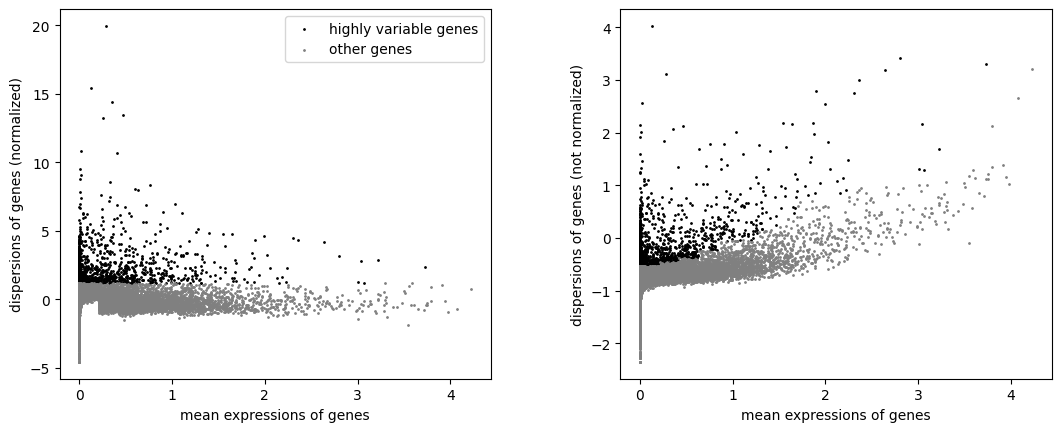

In [ ]:
# Display the top 20 highly variable genes
hvg_table = adata.var.loc[adata.var["highly_variable"]].copy()

sort_column = (
    "variances_norm"
    if "variances_norm" in hvg_table.columns
    else "dispersions_norm"
    if "dispersions_norm" in hvg_table.columns
    else None
)

if sort_column:
    hvg_table = hvg_table.sort_values(
        sort_column, ascending=False
    )

print("Top 20 highly variable genes:")
print(hvg_table.head(20))

# Plot HVG selection
sc.pl.highly_variable_genes(adata)

###Run PCA

####Preserve normalized expression and subset HVGs
Saves the log-normalized expression in a layer and creates a separate AnnData object containing the
selected highly variable genes. Keeping this object separate allows scaling and dimensionality reduction
without overwriting the full expression matrix.

In [ ]:
# Preserve log-normalized expression before scaling
if "log1p_norm" not in adata.layers:
    adata.layers["log1p_norm"] = adata.X.copy()

# Create a separate object containing only highly variable genes
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

print("HVG object:", adata_hvg)
print("Raw counts preserved:", "counts" in adata_hvg.layers)
print("Log-normalized expression preserved:", "log1p_norm" in adata_hvg.layers)

HVG object: AnnData object with n_obs × n_vars = 2400 × 2000
    obs: 'sample_prefix', 'total_counts', 'detected_genes', 'pct_mito'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: 'counts', 'log1p_norm'
Raw counts preserved: True
Log-normalized expression preserved: True


###Scale HVGs and run PCA
Scales the highly variable gene matrix, limits extreme scaled values, and computes principal components.
PCA compresses correlated gene-expression patterns into a smaller set of dimensions for visualization
and neighborhood construction

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


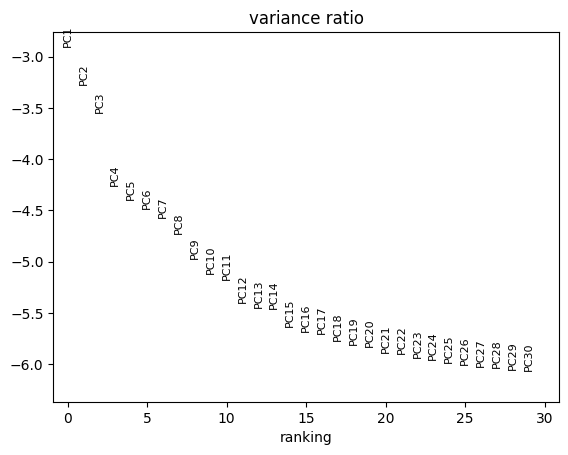

PCA coordinates shape: (2400, 30)


In [ ]:
# Scale the highly variable genes
sc.pp.scale(
    adata_hvg,
    zero_center=True,
    max_value=10
)

# Calculate principal components
sc.tl.pca(
    adata_hvg,
    n_comps=30,
    random_state=42
)

# Plot variance explained
sc.pl.pca_variance_ratio(
    adata_hvg,
    n_pcs=30,
    log=True
)

print("PCA coordinates shape:", adata_hvg.obsm["X_pca"].shape)

### Inspect the PCA embedding
Extracts the first two principal components into a table and visualizes or summarizes the distribution of
cells in PC space. This is a diagnostic view of major expression variation, not proof that clusters
correspond to distinct biological cell types.

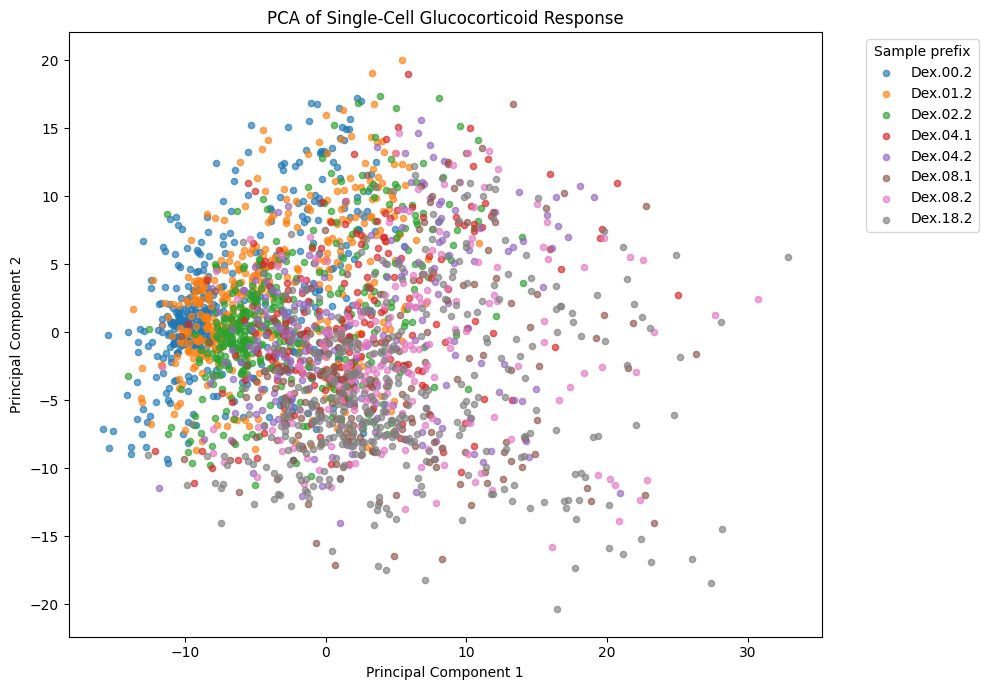

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract the first two principal components
pca_df = pd.DataFrame(
    adata_hvg.obsm["X_pca"][:, :2],
    columns=["PC1", "PC2"],
    index=adata_hvg.obs_names
)

# Add sample labels
pca_df["sample_prefix"] = adata_hvg.obs["sample_prefix"].values

# Create the plot
plt.figure(figsize=(10, 7))

for group in sorted(pca_df["sample_prefix"].unique()):
    subset = pca_df[pca_df["sample_prefix"] == group]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=group,
        alpha=0.65,
        s=20
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Single-Cell Glucocorticoid Response")
plt.legend(title="Sample prefix", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

###Build the neighbor graph and calculate **UMAP**
Constructs a cell-neighborhood graph using the selected principal components and calculates a UMAP
embedding. UMAP is used to visualize local similarities in expression profiles; distances and apparent
clusters should not be overinterpreted as definitive biological groups.

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

# Build the neighborhood graph using the PCA results
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=15,
    n_pcs=20,
    random_state=42
)

# Calculate UMAP coordinates
sc.tl.umap(
    adata_hvg,
    random_state=42
)

print("UMAP coordinates:", adata_hvg.obsm["X_umap"].shape)

UMAP coordinates: (2400, 2)


### Visualize UMAP by sample prefix
Plots the UMAP embedding with cells coloured by sample prefix. This checks whether the embedding is
dominated by sample-specific structure and helps identify potential batch or sample effects.

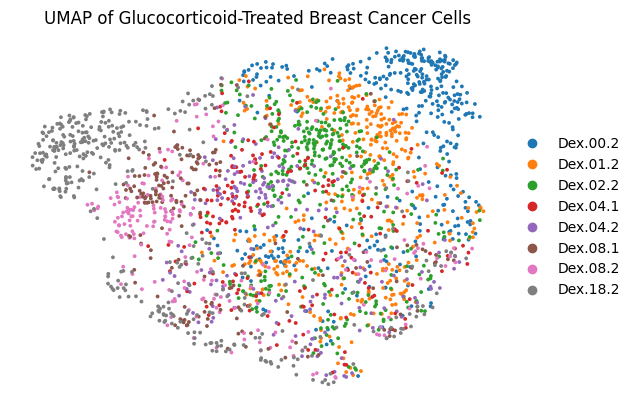

In [ ]:
sc.pl.umap(
    adata_hvg,
    color="sample_prefix",
    title="UMAP of Glucocorticoid-Treated Breast Cancer Cells",
    frameon=False,
    legend_loc="right margin",
    size=30
)

###Summarize QC by sample prefix
Aggregates cell counts and QC metrics by sample prefix. This allows comparison of sample composition
and cell quality rather than relying only on pooled-cell summaries.

In [ ]:
import pandas as pd

sample_summary = (
    adata.obs.groupby("sample_prefix", observed=True)
    .agg(
        n_cells=("sample_prefix", "size"),
        mean_detected_genes=("detected_genes", "mean"),
        mean_total_counts=("total_counts", "mean"),
        mean_mito_pct=("pct_mito", "mean")
    )
    .round(2)
)

display(sample_summary)

,n_cells,mean_detected_genes,mean_total_counts,mean_mito_pct
sample_prefix,,,,
Dex.00.2,400,6105.02,26550.72,0.47
Dex.01.2,400,6371.14,29042.06,0.52
Dex.02.2,400,6546.26,30500.20,0.47
Dex.04.1,193,6430.38,29331.92,0.99
Dex.04.2,207,6544.06,29761.32,0.76
Dex.08.1,189,6465.68,30972.04,1.01
Dex.08.2,211,6516.79,29724.42,0.93
Dex.18.2,400,6485.83,30725.43,0.44


###Review available prefixes and their cell counts
Prints the observed sample prefixes and cell counts in sorted order. This is a consistency check on the
metadata attached to the AnnData object.

In [ ]:
print("Available sample prefixes:")
print(sorted(adata.obs["sample_prefix"].unique()))

print("\nCell counts by prefix:")
print(adata.obs["sample_prefix"].value_counts().sort_index())

Available sample prefixes:
['Dex.00.2', 'Dex.01.2', 'Dex.02.2', 'Dex.04.1', 'Dex.04.2', 'Dex.08.1', 'Dex.08.2', 'Dex.18.2']

Cell counts by prefix:
sample_prefix
Dex.00.2    400
Dex.01.2    400
Dex.02.2    400
Dex.04.1    193
Dex.04.2    207
Dex.08.1    189
Dex.08.2    211
Dex.18.2    400
Name: count, dtype: int64


###Repeat the prefix count check
Repeats the prefix inventory as an explicit verification step. It is redundant with the preceding summary
but can help confirm that no expected prefix was lost during object creation or filtering.

In [ ]:
print("Unique sample prefixes:")
print(sorted(adata.obs["sample_prefix"].unique()))

print("\nCells per sample prefix:")
print(adata.obs["sample_prefix"].value_counts().sort_index())

Unique sample prefixes:
['Dex.00.2', 'Dex.01.2', 'Dex.02.2', 'Dex.04.1', 'Dex.04.2', 'Dex.08.1', 'Dex.08.2', 'Dex.18.2']

Cells per sample prefix:
sample_prefix
Dex.00.2    400
Dex.01.2    400
Dex.02.2    400
Dex.04.1    193
Dex.04.2    207
Dex.08.1    189
Dex.08.2    211
Dex.18.2    400
Name: count, dtype: int64


###Retrieve GEO family metadata
Downloads the GEO family SOFT metadata file and inspects its contents to connect the cell-ID prefixes
with study/sample annotations. The metadata file is used to support, rather than guess, the treatment
time mapping.

In [ ]:
import gzip
import requests

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE141nnn/GSE141834/soft/GSE141834_family.soft.gz"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

geo_text = gzip.decompress(response.content).decode(
    "utf-8", errors="replace"
)

# Extract individual sample records
sample_records = []
current_record = []

for line in geo_text.splitlines():
    if line.startswith("^SAMPLE"):
        if current_record:
            sample_records.append(current_record)
        current_record = [line]
    elif current_record:
        current_record.append(line)

if current_record:
    sample_records.append(current_record)

# Display important fields from each record
for record in sample_records:
    relevant = [
        line for line in record
        if line.startswith((
            "!Sample_geo_accession",
            "!Sample_title",
            "!Sample_source_name_ch1",
            "!Sample_characteristics_ch1",
            "!Sample_library_strategy",
            "!Sample_relation",
            "!Sample_description"
        ))
    ]

    print("\n".join(relevant))
    print("-" * 60)

!Sample_title = A1-2 cells, EtOH_rep1, Bulk RNAseq
!Sample_geo_accession = GSM4213967
!Sample_source_name_ch1 = A1-2 breast cancer cells
!Sample_characteristics_ch1 = cell type: A1-2 breast cancer cells
!Sample_characteristics_ch1 = treatment: 18hr EtOH
!Sample_description = bulkRNAseq_normalized_counts.txt
!Sample_library_strategy = RNA-Seq
!Sample_relation = BioSample: https://www.ncbi.nlm.nih.gov/biosample/SAMN13541125
!Sample_relation = SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX7347916
------------------------------------------------------------
!Sample_title = A1-2 cells, EtOH_rep2, Bulk RNAseq
!Sample_geo_accession = GSM4213968
!Sample_source_name_ch1 = A1-2 breast cancer cells
!Sample_characteristics_ch1 = cell type: A1-2 breast cancer cells
!Sample_characteristics_ch1 = treatment: 18hr EtOH
!Sample_description = bulkRNAseq_normalized_counts.txt
!Sample_library_strategy = RNA-Seq
!Sample_relation = BioSample: https://www.ncbi.nlm.nih.gov/biosample/SAMN13541124
!Sample_relati

###Create a cell-count summary by prefix
Builds a sorted table of cell counts for each sample prefix. This provides a concise count summary that
can be compared with the metadata and earlier inspection.

In [ ]:
import pandas as pd

# Count cells belonging to each prefix
prefix_summary = (
    adata.obs["sample_prefix"]
    .value_counts()
    .sort_index()
    .rename_axis("sample_prefix")
    .reset_index(name="n_cells")
)

display(prefix_summary)

,sample_prefix,n_cells
0,Dex.00.2,400
1,Dex.01.2,400
2,Dex.02.2,400
3,Dex.04.1,193
4,Dex.04.2,207
5,Dex.08.1,189
6,Dex.08.2,211
7,Dex.18.2,400


###Check dataset size and unique prefixes
Reports the total cells, number of unique prefixes, and the prefixes observed. This documents the final
dataset structure at this stage of the workflow

In [ ]:
print("Total cells:", adata.n_obs)
print("Unique cell prefixes:", adata.obs["sample_prefix"].nunique())

print("\nCell prefixes:")
for prefix in sorted(adata.obs["sample_prefix"].unique()):
    print(prefix)

Total cells: 2400
Unique cell prefixes: 8

Cell prefixes:
Dex.00.2
Dex.01.2
Dex.02.2
Dex.04.1
Dex.04.2
Dex.08.1
Dex.08.2
Dex.18.2


###Inspect representative cell IDs per prefix
Prints example cell identifiers for each prefix to verify how the identifiers are formatted. This helps
validate the rule used to extract sample prefixes.

In [ ]:
# Inspect example cell IDs from each prefix
for prefix in sorted(adata.obs["sample_prefix"].unique()):
    print(f"\n{prefix}")
    print(adata.obs_names[
        adata.obs["sample_prefix"] == prefix
    ][:5].tolist())


Dex.00.2
['Dex.00.2_AGGTTATCGCCTATATAC', 'Dex.00.2_CTATTACTATTAGTCCTA', 'Dex.00.2_CAAGTCATCCGGGGACGA', 'Dex.00.2_ACCTTCTAATAGTGCTAA', 'Dex.00.2_TCGCCTAAAGAACATAGA']

Dex.01.2
['Dex.01.2_TTGGATCCGATGATGAAG', 'Dex.01.2_GCCAGAAGACCCAAGCCA', 'Dex.01.2_CTCAATCCGATGAGTCTG', 'Dex.01.2_TTCTTGGCCGTTCACTGT', 'Dex.01.2_AGTCTGACTGCACTTGAA']

Dex.02.2
['Dex.02.2_CCGTAAATACTTTGCTAA', 'Dex.02.2_AGACCCTGAGACTGGCAG', 'Dex.02.2_CAACCGCTTACGTCGGGA', 'Dex.02.2_CCTCTAGGCCATATACTT', 'Dex.02.2_TCGCCTGGTAGGACGGAC']

Dex.04.1
['Dex.04.1_TAAGCTGAGCTTAGCACG', 'Dex.04.1_CGAGCACTTACGTACCGA', 'Dex.04.1_GAAATACGTTATAGACCC', 'Dex.04.1_AGTCTGTAAGCTTAATAG', 'Dex.04.1_CGGTCCGCTGAGTTGGAT']

Dex.04.2
['Dex.04.2_TGTTCGTGTGTACGCATA', 'Dex.04.2_TGCGGTGGGATCGAGTGA', 'Dex.04.2_ATCCGGTGTTCGAGTAAA', 'Dex.04.2_ATAGCGCAAGTCCAAGTC', 'Dex.04.2_TCAGTGGACTCGTAGAGG']

Dex.08.1
['Dex.08.1_GCCAGATTGCTCTGTGTA', 'Dex.08.1_CGAAAGACGGACGAGTGA', 'Dex.08.1_GTCCTAGAGTGACTAGGT', 'Dex.08.1_GCTGAGCCGTAAGGACGA', 'Dex.08.1_CATAGAGCGAATAGACCC']

Dex

###Inspect original matrix dimensions and IDs
Displays the original matrix dimensions and selected cell identifiers. This cross-checks the relationship
between raw matrix columns and the sample-prefix metadata.

In [ ]:
print("Original matrix dimensions:", counts.shape)

print("\nFirst 15 original cell IDs:")
print(counts.columns[:15].tolist())

print("\nExample IDs around the treatment groups:")
for prefix in sorted(adata.obs["sample_prefix"].unique()):
    matching = [
        cell for cell in counts.columns
        if str(cell).startswith(prefix)
    ]
    print(prefix, "->", matching[:3])

Original matrix dimensions: (32049, 2400)

First 15 original cell IDs:
['Dex.00.2_AGGTTATCGCCTATATAC', 'Dex.00.2_CTATTACTATTAGTCCTA', 'Dex.00.2_CAAGTCATCCGGGGACGA', 'Dex.00.2_ACCTTCTAATAGTGCTAA', 'Dex.00.2_TCGCCTAAAGAACATAGA', 'Dex.00.2_GAGGCCACAAGGACAAGG', 'Dex.00.2_GGATTGCTGTGGGCTTGT', 'Dex.00.2_CGTTATCTGTGGCTGTGG', 'Dex.00.2_TCGGGAAGTAAACAAGTC', 'Dex.00.2_GTACAGGGTAGGGAGGCC', 'Dex.00.2_CCGATGTGAGACGCTTGT', 'Dex.00.2_TTAAGAAACAGCTTAAGA', 'Dex.00.2_GCTTGTTGTTCGTTAAGA', 'Dex.00.2_AAGCCACTGTGGATAGCG', 'Dex.00.2_GCGAATACCCAATTCTTG']

Example IDs around the treatment groups:
Dex.00.2 -> ['Dex.00.2_AGGTTATCGCCTATATAC', 'Dex.00.2_CTATTACTATTAGTCCTA', 'Dex.00.2_CAAGTCATCCGGGGACGA']
Dex.01.2 -> ['Dex.01.2_TTGGATCCGATGATGAAG', 'Dex.01.2_GCCAGAAGACCCAAGCCA', 'Dex.01.2_CTCAATCCGATGAGTCTG']
Dex.02.2 -> ['Dex.02.2_CCGTAAATACTTTGCTAA', 'Dex.02.2_AGACCCTGAGACTGGCAG', 'Dex.02.2_CAACCGCTTACGTCGGGA']
Dex.04.1 -> ['Dex.04.1_TAAGCTGAGCTTAGCACG', 'Dex.04.1_CGAGCACTTACGTACCGA', 'Dex.04.1_GAAATACGTTATAGACCC

###Map sample prefixes to treatment times
Defines the mapping from sample prefixes to the control and dexamethasone exposure time points, then
attaches the resulting
treatment_time metadata to cells. Correct mapping is essential because all time
course comparisons depend on it.

In [ ]:
import numpy as np
import pandas as pd

# Map sample prefixes to treatment times
time_mapping = {
    "Dex.00.2": "0h_Control",
    "Dex.01.2": "1h",
    "Dex.02.2": "2h",
    "Dex.04.1": "4h",
    "Dex.04.2": "4h",
    "Dex.08.1": "8h",
    "Dex.08.2": "8h",
    "Dex.18.2": "18h"
}

adata.obs["treatment_time"] = (
    adata.obs["sample_prefix"].map(time_mapping)
)

print(adata.obs["treatment_time"].value_counts())

treatment_time
0h_Control    400
1h            400
2h            400
4h            400
8h            400
18h           400
Name: count, dtype: int64


###Calculate average expression by time point
Calculates mean expression for each gene within each treatment-time group using the normalized
expression matrix. The means support descriptive time-course comparisons; they do not by themselves
provide statistical evidence of differential expression.

In [ ]:
from scipy import sparse

expression = adata.X

if sparse.issparse(expression):
    expression = expression.toarray()

expression = pd.DataFrame(
    expression,
    index=adata.obs_names,
    columns=adata.var_names
)

expression["treatment_time"] = adata.obs["treatment_time"].values

mean_expression = expression.groupby("treatment_time").mean().T

print("Mean-expression matrix:", mean_expression.shape)
display(mean_expression.iloc[:5, :])

Mean-expression matrix: (32049, 6)


treatment_time,0h_Control,18h,1h,2h,4h,8h
CTSH,0.201001,0.144096,0.140111,0.179188,0.183647,0.177703
SFXN4,0.278399,0.295259,0.333571,0.310839,0.304014,0.267314
AC127537.3,0.001953,0.000872,0.005519,0.001263,0.001729,0.006553
DCAF8L1,0.001531,0.003694,0.002271,0.003899,0.003741,0.006072
RBM45,0.099074,0.075310,0.085522,0.093563,0.097317,0.113241


###Rank genes by change from control
Compares mean expression at each treatment time with the control mean and ranks genes by the size of
their expression changes. This is a descriptive screen for candidate genes and does not account for
biological replicate variability

In [ ]:
import pandas as pd
import numpy as np

control = mean_expression["0h_Control"]

time_points = ["1h", "2h", "4h", "8h", "18h"]

ranked_changes = {}

for time in time_points:
    difference = mean_expression[time] - control

    result = pd.DataFrame({
        "gene": mean_expression.index,
        "control_mean": control.values,
        "treated_mean": mean_expression[time].values,
        "difference": difference.values,
        "absolute_difference": np.abs(difference.values)
    })

    result = result.sort_values(
        "absolute_difference",
        ascending=False
    )

    ranked_changes[time] = result

    print(f"\nTop 15 genes at {time} vs control:")
    display(result.head(15))


Top 15 genes at 1h vs control:


,gene,control_mean,treated_mean,difference,absolute_difference
8284,NFKBIA,0.379479,1.314239,0.934760,0.934760
3683,EEF1A1,1.001502,1.770025,0.768522,0.768522
14666,PIP,3.745106,3.054988,-0.690119,0.690119
16732,HSPA1A,1.235020,0.562492,-0.672529,0.672529
8282,RPS10,2.167158,1.676427,-0.490731,0.490731
5977,RPL10,1.620945,2.108460,0.487516,0.487516
14175,BCL6,0.288277,0.769794,0.481517,0.481517
15008,HSPB1,3.406845,2.943062,-0.463784,0.463784
16040,S100A11,3.185012,2.757348,-0.427664,0.427664
6613,NUPR1,1.835748,1.431260,-0.404488,0.404488



Top 15 genes at 2h vs control:


,gene,control_mean,treated_mean,difference,absolute_difference
8284,NFKBIA,0.379479,1.301931,0.922452,0.922452
3683,EEF1A1,1.001502,1.864390,0.862887,0.862887
16732,HSPA1A,1.235020,0.519285,-0.715736,0.715736
20523,FKBP5,0.691363,1.355385,0.664022,0.664022
11129,CEBPD,0.178454,0.824188,0.645735,0.645735
22208,TIPARP,0.176397,0.741880,0.565483,0.565483
5977,RPL10,1.620945,2.185595,0.564650,0.564650
14175,BCL6,0.288277,0.784484,0.496208,0.496208
17083,GLUL,0.821823,1.286426,0.464603,0.464603
20943,PRR15L,0.275644,0.736098,0.460454,0.460454



Top 15 genes at 4h vs control:


,gene,control_mean,treated_mean,difference,absolute_difference
20523,FKBP5,0.691363,1.971562,1.280199,1.280199
8284,NFKBIA,0.379479,1.202946,0.823467,0.823467
11129,CEBPD,0.178454,0.957174,0.778721,0.778721
17083,GLUL,0.821823,1.585801,0.763979,0.763979
9031,IER3,1.199254,0.527783,-0.671471,0.671471
14666,PIP,3.745106,3.074930,-0.670177,0.670177
3683,EEF1A1,1.001502,1.660840,0.659338,0.659338
127,AC093323.1,0.820321,1.478488,0.658167,0.658167
16714,MT-ND4,1.958656,2.603533,0.644877,0.644877
20484,ATAD2,0.786179,1.421741,0.635562,0.635562



Top 15 genes at 8h vs control:


,gene,control_mean,treated_mean,difference,absolute_difference
20523,FKBP5,0.691363,2.268387,1.577024,1.577024
2938,S100P,1.562130,2.811404,1.249274,1.249274
11129,CEBPD,0.178454,1.043585,0.865131,0.865131
17083,GLUL,0.821823,1.683523,0.861700,0.861700
3683,EEF1A1,1.001502,1.823029,0.821527,0.821527
8832,PNMT,0.072447,0.887639,0.815192,0.815192
16714,MT-ND4,1.958656,2.754375,0.795718,0.795718
20039,NEAT1,1.269481,2.063350,0.793869,0.793869
8284,NFKBIA,0.379479,1.167042,0.787564,0.787564
20975,MT-CO1,0.818484,1.600293,0.781809,0.781809



Top 15 genes at 18h vs control:


,gene,control_mean,treated_mean,difference,absolute_difference
2938,S100P,1.562130,3.312569,1.750439,1.750439
20523,FKBP5,0.691363,2.170685,1.479321,1.479321
19968,ACSL1,0.295864,1.491357,1.195493,1.195493
8832,PNMT,0.072447,1.175400,1.102953,1.102953
17651,AZGP1,0.924694,1.968050,1.043355,1.043355
1595,ELOVL5,1.032651,1.980291,0.947641,0.947641
16998,KCNMA1,0.279604,1.176754,0.897151,0.897151
783,FASN,1.465321,2.339213,0.873892,0.873892
17083,GLUL,0.821823,1.687465,0.865642,0.865642
20434,FXYD3,1.220266,2.068010,0.847744,0.847744


###Plot selected gene trajectories
Plots mean expression over time for selected genes such as FKBP5, NFKBIA, CEBPD, GLUL, and S100P.
These trajectories help distinguish early, sustained, and later expression patterns.

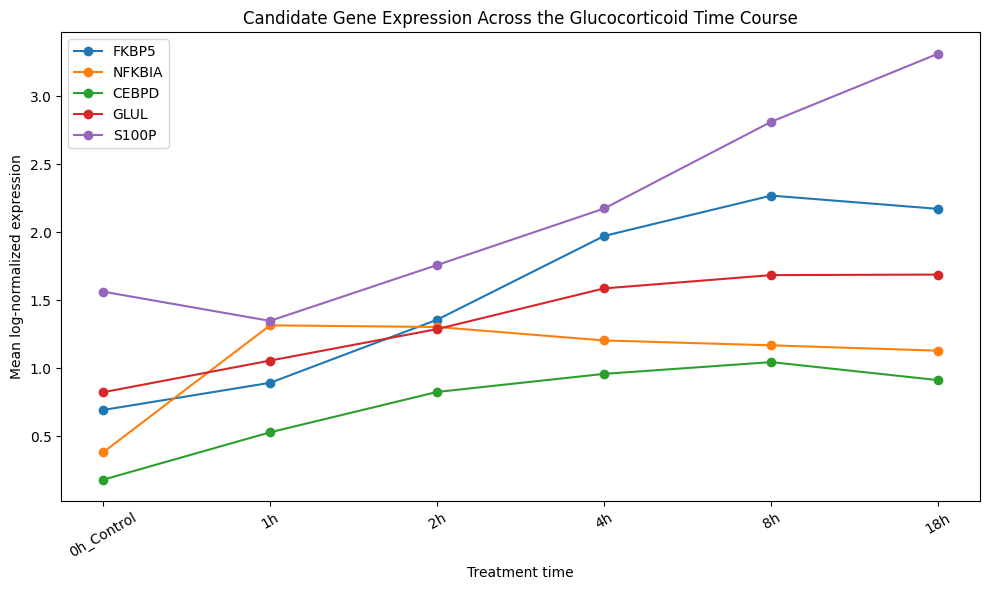

In [ ]:
import matplotlib.pyplot as plt

genes_of_interest = [
    "FKBP5",
    "NFKBIA",
    "CEBPD",
    "GLUL",
    "S100P"
]

time_order = [
    "0h_Control", "1h", "2h", "4h", "8h", "18h"
]

available_genes = [
    gene for gene in genes_of_interest
    if gene in mean_expression.index
]

plt.figure(figsize=(10, 6))

for gene in available_genes:
    plt.plot(
        time_order,
        mean_expression.loc[gene, time_order],
        marker="o",
        label=gene
    )

plt.xlabel("Treatment time")
plt.ylabel("Mean log-normalized expression")
plt.title("Candidate Gene Expression Across the Glucocorticoid Time Course")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

###Inspect single-cell expression distributions
Visualizes expression of selected genes at representative time points. Single-cell plots reveal
heterogeneity that can be hidden by group means, including cells with low or high detected expression.

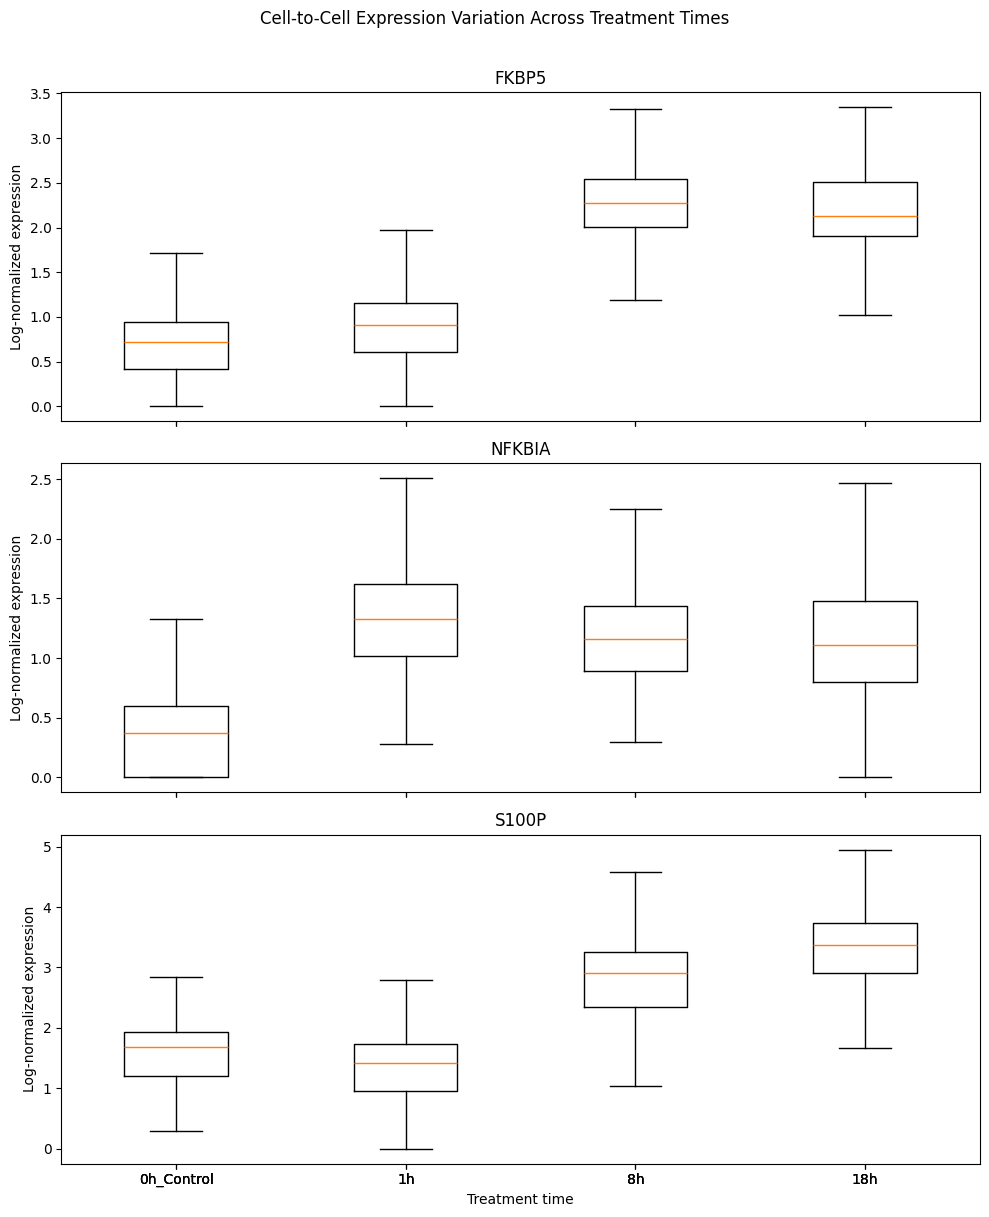

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import sparse

genes = ["FKBP5", "NFKBIA", "S100P"]
times = ["0h_Control", "1h", "8h", "18h"]

# Confirm that all requested genes exist
genes = [g for g in genes if g in adata.var_names]

fig, axes = plt.subplots(
    len(genes), 1,
    figsize=(10, 4 * len(genes)),
    sharex=True
)

if len(genes) == 1:
    axes = [axes]

for ax, gene in zip(axes, genes):
    gene_idx = adata.var_names.get_loc(gene)
    values = adata.X[:, gene_idx]

    if sparse.issparse(values):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()

    plot_df = pd.DataFrame({
        "time": adata.obs["treatment_time"].values,
        "expression": values
    })

    plot_df = plot_df[plot_df["time"].isin(times)]

    data = [
        plot_df.loc[plot_df["time"] == t, "expression"].values
        for t in times
    ]

    ax.boxplot(data, tick_labels=times, showfliers=False)
    ax.set_title(gene)
    ax.set_ylabel("Log-normalized expression")

axes[-1].set_xlabel("Treatment time")
plt.suptitle(
    "Cell-to-Cell Expression Variation Across Treatment Times",
    y=1.01
)
plt.tight_layout()
plt.show()

 ###Quantify single-cell gene-expression heterogeneity
Summarizes the distribution of selected gene expression across individual cells and treatment times. This
provides a descriptive measure of how broadly or unevenly each gene's expression is detected.

In [ ]:
import numpy as np
import pandas as pd
from scipy import sparse

genes = ["FKBP5", "NFKBIA", "S100P"]
times = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

results = []

for gene in genes:
    gene_idx = adata.var_names.get_loc(gene)

    values = adata.X[:, gene_idx]
    if sparse.issparse(values):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()

    df = pd.DataFrame({
        "time": adata.obs["treatment_time"].values,
        "expression": values
    })

    for time in times:
        x = df.loc[df["time"] == time, "expression"].values

        results.append({
            "gene": gene,
            "time": time,
            "cells": len(x),
            "median_expression": np.median(x),
            "IQR": np.percentile(x, 75) - np.percentile(x, 25),
            "percent_expressing": 100 * np.mean(x > 0)
        })

results_df = pd.DataFrame(results)

display(
    results_df.round(3)
)

,gene,time,cells,median_expression,IQR,percent_expressing
0,FKBP5,0h_Control,400,0.717,0.521,87.75
1,FKBP5,1h,400,0.905,0.556,92.00
2,FKBP5,2h,400,1.365,0.524,98.50
3,FKBP5,4h,400,1.975,0.541,99.75
4,FKBP5,8h,400,2.269,0.543,100.00
5,FKBP5,18h,400,2.134,0.605,100.00
6,NFKBIA,0h_Control,400,0.373,0.600,68.75
7,NFKBIA,1h,400,1.330,0.597,98.25
8,NFKBIA,2h,400,1.254,0.542,99.50
9,NFKBIA,4h,400,1.206,0.638,97.00


###Visualize cells contributing to selected gene signals
Examines the cell-level expression patterns of FKBP5 and S100P across time. The aim is to see whether
the average response reflects broad shifts or a subset of high-expressing cells.

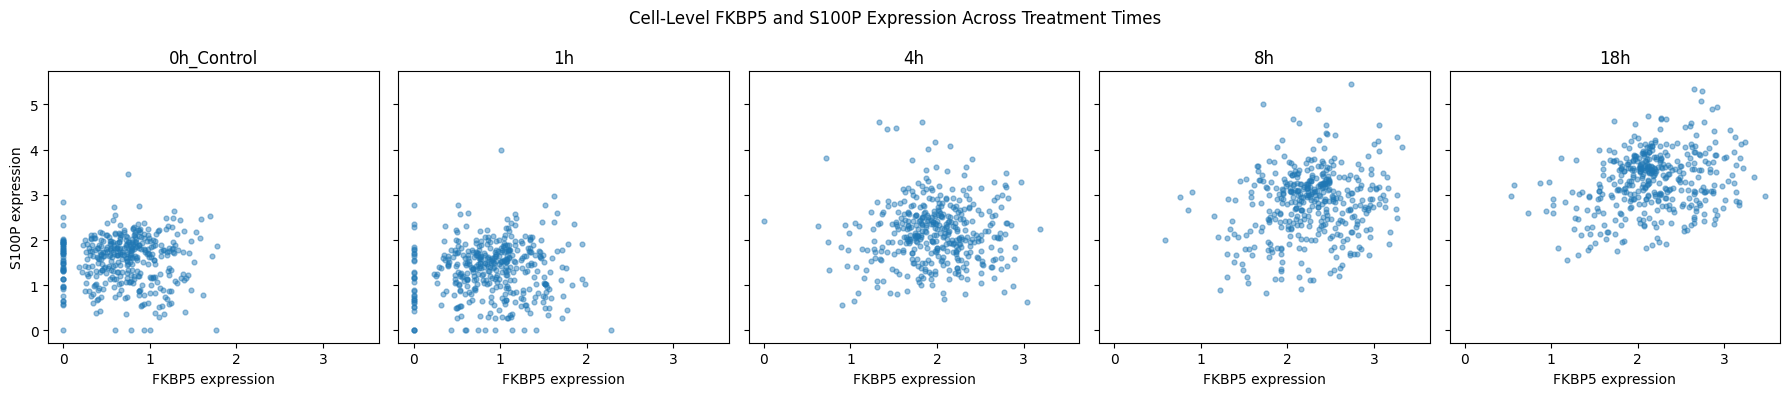

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse

genes = ["FKBP5", "S100P"]
times = ["0h_Control", "1h", "4h", "8h", "18h"]

gene_values = {}

for gene in genes:
    idx = adata.var_names.get_loc(gene)
    values = adata.X[:, idx]

    if sparse.issparse(values):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()

    gene_values[gene] = values

fig, axes = plt.subplots(1, len(times), figsize=(18, 4), sharex=True, sharey=True)

for ax, time in zip(axes, times):
    mask = adata.obs["treatment_time"].values == time

    ax.scatter(
        gene_values["FKBP5"][mask],
        gene_values["S100P"][mask],
        alpha=0.45,
        s=12
    )

    ax.set_title(time)
    ax.set_xlabel("FKBP5 expression")

axes[0].set_ylabel("S100P expression")
fig.suptitle("Cell-Level FKBP5 and S100P Expression Across Treatment Times")
plt.tight_layout()
plt.show()

 ###Measure FKBP5–S100P association
Calculates Spearman correlations between FKBP5 and S100P expression within treatment-time groups.
Correlation indicates co-variation, not direct regulation or a causal relationship

In [ ]:
import pandas as pd
import numpy as np
from scipy import sparse
from scipy.stats import spearmanr

genes = ["FKBP5", "S100P"]
times = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

expression = {}

for gene in genes:
    idx = adata.var_names.get_loc(gene)
    values = adata.X[:, idx]

    if sparse.issparse(values):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()

    expression[gene] = values

results = []

for time in times:
    mask = adata.obs["treatment_time"].values == time

    rho, p_value = spearmanr(
        expression["FKBP5"][mask],
        expression["S100P"][mask]
    )

    results.append({
        "time": time,
        "Spearman_rho": rho,
        "p_value": p_value
    })

correlation_df = pd.DataFrame(results)
display(correlation_df.round(4))

,time,Spearman_rho,p_value
0,0h_Control,0.0454,0.3656
1,1h,0.0520,0.2996
2,2h,-0.0023,0.9632
3,4h,0.0254,0.6130
4,8h,0.1449,0.0037
5,18h,0.2136,0.0000


###Compare broader expression changes across time
Builds a table of gene-expression changes relative to control for all selected treatment times. This extends
the analysis beyond a few hand-selected genes to identify broader temporal patterns.

In [ ]:
import pandas as pd
import numpy as np

control = mean_expression["0h_Control"]

comparisons = ["1h", "2h", "4h", "8h", "18h"]
change_data = pd.DataFrame(index=mean_expression.index)

for time in comparisons:
    change_data[f"{time}_log_expression"] = mean_expression[time]
    change_data[f"{time}_change_vs_control"] = (
        mean_expression[time] - control
    )

# Rank genes by the magnitude of their expression change at 18h
change_data["absolute_change_18h"] = (
    change_data["18h_change_vs_control"].abs()
)

ranked_genes = change_data.sort_values(
    "absolute_change_18h",
    ascending=False
)

display(ranked_genes.head(30).round(3))

,1h_log_expression,1h_change_vs_control,2h_log_expression,2h_change_vs_control,4h_log_expression,4h_change_vs_control,8h_log_expression,8h_change_vs_control,18h_log_expression,18h_change_vs_control,absolute_change_18h
S100P,1.347,-0.215,1.758,0.196,2.174,0.611,2.811,1.249,3.313,1.750,1.750
FKBP5,0.891,0.200,1.355,0.664,1.972,1.280,2.268,1.577,2.171,1.479,1.479
ACSL1,0.365,0.069,0.426,0.130,0.587,0.291,1.033,0.737,1.491,1.195,1.195
PNMT,0.069,-0.003,0.179,0.106,0.479,0.406,0.888,0.815,1.175,1.103,1.103
AZGP1,0.570,-0.355,0.739,-0.185,0.957,0.033,1.446,0.521,1.968,1.043,1.043
ELOVL5,1.055,0.023,1.114,0.081,1.349,0.317,1.610,0.578,1.980,0.948,0.948
KCNMA1,0.244,-0.036,0.367,0.088,0.478,0.199,0.855,0.575,1.177,0.897,0.897
FASN,1.417,-0.048,1.530,0.065,1.767,0.301,2.050,0.584,2.339,0.874,0.874
GLUL,1.055,0.233,1.286,0.465,1.586,0.764,1.684,0.862,1.687,0.866,0.866
FXYD3,1.063,-0.158,1.196,-0.024,1.265,0.045,1.653,0.433,2.068,0.848,0.848


###Classify temporal response patterns
Uses each gene's mean-expression trajectory to assign a descriptive temporal pattern. These categories
simplify the time course but depend on the classification rules and should not be treated as
independently validated gene classes.

In [ ]:
import numpy as np
import pandas as pd

times = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

# Mean expression at each time point
trajectory = mean_expression[times].copy()

# Change relative to control
change = trajectory.subtract(
    trajectory["0h_Control"], axis=0
)

# Classify using exploratory thresholds
def classify_pattern(row):
    early = row[["1h", "2h"]].mean()
    late = row[["8h", "18h"]].mean()
    peak = row[["1h", "2h", "4h", "8h", "18h"]].max()
    trough = row[["1h", "2h", "4h", "8h", "18h"]].min()

    if late >= 0.5 and late > early + 0.25:
        return "Delayed increase"

    elif early >= 0.5 and late >= 0.5:
        return "Sustained increase"

    elif early >= 0.5 and late < early - 0.25:
        return "Transient increase"

    elif late <= -0.5 and late < early - 0.25:
        return "Delayed decrease"

    elif early <= -0.5 and late <= -0.5:
        return "Sustained decrease"

    elif early <= -0.5 and late > early + 0.25:
        return "Transient decrease"

    else:
        return "Other/mixed"

patterns = pd.DataFrame(index=change.index)
patterns["pattern"] = change.apply(classify_pattern, axis=1)
patterns["change_1h"] = change["1h"]
patterns["change_4h"] = change["4h"]
patterns["change_8h"] = change["8h"]
patterns["change_18h"] = change["18h"]

print("Genes per exploratory pattern:")
display(patterns["pattern"].value_counts().to_frame("gene_count"))

print("\nExamples from each pattern:")
for pattern in patterns["pattern"].unique():
    print(f"\n{pattern}")
    display(
        patterns[patterns["pattern"] == pattern]
        .sort_values("change_18h", ascending=False)
        .head(5)
        .round(3)
    )

Genes per exploratory pattern:


,gene_count
pattern,
Other/mixed,32003
Delayed increase,37
Delayed decrease,6
Sustained increase,2
Sustained decrease,1



Examples from each pattern:

Other/mixed


,pattern,change_1h,change_4h,change_8h,change_18h
BCL6,Other/mixed,0.482,0.241,0.411,0.681
ELF5,Other/mixed,0.027,0.116,0.392,0.598
KRT80,Other/mixed,0.102,0.074,0.397,0.564
BNIP3,Other/mixed,0.052,0.140,0.308,0.560
C5orf38,Other/mixed,-0.115,0.022,0.299,0.538



Delayed increase


...

,pattern,change_1h,change_4h,change_8h,change_18h
NFKBIA,Sustained increase,0.935,0.823,0.788,0.748
EEF1A1,Sustained increase,0.769,0.659,0.822,0.422



Delayed decrease


,pattern,change_1h,change_4h,change_8h,change_18h
IER3,Delayed decrease,-0.157,-0.671,-0.682,-0.470
PLK2,Delayed decrease,-0.132,-0.579,-0.500,-0.500
CRABP2,Delayed decrease,-0.174,-0.306,-0.440,-0.645
SERPINA6,Delayed decrease,-0.295,-0.317,-0.383,-0.692
LMO4,Delayed decrease,0.023,-0.283,-0.500,-0.772



Sustained decrease


,pattern,change_1h,change_4h,change_8h,change_18h
HSPA1A,Sustained decrease,-0.673,-0.623,-0.486,-0.632


###DE

####Run exploratory cell-level differential expression
Uses Scanpy to compare each treatment time with the control group and stores the resulting differential
expression tables. Because the tests treat cells as observations and the dataset has limited sample-level
replication, the results are exploratory and may be affected by pseudoreplication.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
from scipy import sparse
from pathlib import Path

# Output directory: temporary Colab storage
DE_DIR = Path("/content/glucocorticoid_project/DE_results")
DE_DIR.mkdir(parents=True, exist_ok=True)

# Confirm required objects and metadata
assert "adata" in globals(), "adata is missing. Load the processed AnnData object first."
assert "treatment_time" in adata.obs.columns, "treatment_time is missing."

print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("\nCells per time point:")
print(adata.obs["treatment_time"].value_counts())

# Ensure treatment labels are present
assert adata.obs["treatment_time"].notna().all()

# Treatment comparisons against ethanol vehicle control
control_label = "0h_Control"
treatment_order = ["1h", "2h", "4h", "8h", "18h"]

de_results = {}

for treatment in treatment_order:
    print(f"\nRunning DE: {treatment} vs {control_label}")

    # Subset to the two groups being compared
    mask = adata.obs["treatment_time"].isin([control_label, treatment])
    adata_sub = adata[mask].copy()

    # Set categorical order so positive log-fold changes mean
    # higher expression in the treatment than in control
    adata_sub.obs["DE_group"] = pd.Categorical(
        adata_sub.obs["treatment_time"],
        categories=[control_label, treatment],
        ordered=True
    )

    # Wilcoxon rank-sum test
    sc.tl.rank_genes_groups(
        adata_sub,
        groupby="DE_group",
        groups=[treatment],
        reference=control_label,
        method="wilcoxon",
        use_raw=False,
        pts=True
    )

    # Extract results
    result = sc.get.rank_genes_groups_df(
        adata_sub,
        group=treatment
    )

    result["comparison"] = f"{treatment}_vs_control"

    # Save each comparison
    result.to_csv(
        DE_DIR / f"DE_{treatment}_vs_control.csv",
        index=False
    )

    de_results[treatment] = result

    print("Genes tested:", len(result))
    print("Genes with adjusted p < 0.05:",
          (result["pvals_adj"] < 0.05).sum())

print("\nDE analysis complete.")
print("Results saved to:", DE_DIR)

Cells: 2400
Genes: 32049

Cells per time point:
treatment_time
0h_Control    400
1h            400
2h            400
4h            400
8h            400
18h           400
Name: count, dtype: int64

Running DE: 1h vs 0h_Control
Genes tested: 32049
Genes with adjusted p < 0.05: 1468

Running DE: 2h vs 0h_Control
Genes tested: 32049
Genes with adjusted p < 0.05: 1379

Running DE: 4h vs 0h_Control
Genes tested: 32049
Genes with adjusted p < 0.05: 2491

Running DE: 8h vs 0h_Control
Genes tested: 32049
Genes with adjusted p < 0.05: 2721

Running DE: 18h vs 0h_Control
Genes tested: 32049
Genes with adjusted p < 0.05: 2679

DE analysis complete.
Results saved to: /content/glucocorticoid_project/DE_results


###Summarize differential-expression results
Counts genes passing the adjusted p-value threshold for each comparison and assembles a comparison
level summary. These counts should be interpreted cautiously because cell-level significance can be
inflated when cells from the same biological sample are treated as independent replicates.

In [ ]:
summary = []

for treatment, result in de_results.items():
    significant = result[result["pvals_adj"] < 0.05]

    summary.append({
        "Time": treatment,
        "Genes_tested": len(result),
        "Significant_FDR05": len(significant),
        "Upregulated_FDR05": (
            (significant["logfoldchanges"] > 0).sum()
        ),
        "Downregulated_FDR05": (
            (significant["logfoldchanges"] < 0).sum()
        )
    })

de_summary = pd.DataFrame(summary)
display(de_summary)

,Time,Genes_tested,Significant_FDR05,Upregulated_FDR05,Downregulated_FDR05
0,1h,32049,1468,812,656
1,2h,32049,1379,815,564
2,4h,32049,2491,1522,969
3,8h,32049,2721,1502,1219
4,18h,32049,2679,1532,1147


###Install pathway-enrichment package
Installs GSEApy, which is used to query pathway and gene-set enrichment resources for lists of genes
from the differential-expression analysis.

In [ ]:
!pip -q install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 9.1 MB/s eta 0:00:00


###Run pathway enrichment
Runs enrichment analyses for the selected up- and down-associated gene lists and saves results under a
dedicated pathway-enrichment directory. Enrichment suggests over-represented annotations; it does not
demonstrate pathway activity or causation.

In [ ]:
import gseapy as gp
import pandas as pd
from pathlib import Path

PATHWAY_DIR = Path("/content/glucocorticoid_project/pathway_enrichment")
PATHWAY_DIR.mkdir(parents=True, exist_ok=True)

pathway_results = {}

for time, df in de_results.items():
    print(f"\n{'='*50}")
    print(f"Pathway enrichment: {time} vs control")
    print(f"{'='*50}")

    significant = df[
        (df["pvals_adj"] < 0.05) &
        (df["names"].notna())
    ].copy()

    for direction, subset in [
        ("upregulated", significant[significant["logfoldchanges"] > 0]),
        ("downregulated", significant[significant["logfoldchanges"] < 0])
    ]:
        genes = subset["names"].astype(str).unique().tolist()

        print(f"\n{direction}: {len(genes)} genes")

        if len(genes) < 5:
            print("Too few genes; skipping.")
            continue

        for library in [
            "GO_Biological_Process_2023",
            "KEGG_2021_Human"
        ]:
            try:
                enr = gp.enrichr(
                    gene_list=genes,
                    gene_sets=library,
                    organism="human",
                    outdir=None,
                    cutoff=1.0
                )

                result = enr.results.copy()

                if result.empty:
                    print(f"{library}: no results returned")
                    continue

                result["time"] = time
                result["direction"] = direction
                result["library"] = library

                key = f"{time}_{direction}_{library}"
                pathway_results[key] = result

                safe_library = library.replace("/", "_")
                result.to_csv(
                    PATHWAY_DIR /
                    f"{time}_{direction}_{safe_library}.csv",
                    index=False
                )

                print(f"{library}: {len(result)} terms returned")

            except Exception as e:
                print(f"{library} failed: {e}")

print("\nPathway enrichment finished.")
print("Output directory:", PATHWAY_DIR)


Pathway enrichment: 1h vs control

upregulated: 812 genes
GO_Biological_Process_2023: 3044 terms returned
KEGG_2021_Human: 280 terms returned

downregulated: 656 genes
GO_Biological_Process_2023: 2265 terms returned
KEGG_2021_Human: 250 terms returned

Pathway enrichment: 2h vs control

upregulated: 815 genes
GO_Biological_Process_2023: 2875 terms returned
KEGG_2021_Human: 279 terms returned

downregulated: 564 genes
GO_Biological_Process_2023: 2370 terms returned
KEGG_2021_Human: 258 terms returned

Pathway enrichment: 4h vs control

upregulated: 1522 genes
GO_Biological_Process_2023: 3853 terms returned
KEGG_2021_Human: 302 terms returned

downregulated: 969 genes
GO_Biological_Process_2023: 2905 terms returned
KEGG_2021_Human: 272 terms returned

Pathway enrichment: 8h vs control

upregulated: 1502 genes
GO_Biological_Process_2023: 3802 terms returned
KEGG_2021_Human: 298 terms returned

downregulated: 1219 genes
GO_Biological_Process_2023: 3315 terms returned
KEGG_2021_Human: 286 

###Combine and rank pathway results
Combines pathway tables and ranks terms using their adjusted p-values. The exact interpretation
depends on how the input gene lists were constructed and which reference gene-set libraries were
queried.

In [ ]:
if pathway_results:
    all_pathways = pd.concat(
        pathway_results.values(),
        ignore_index=True
    )

    # Enrichr's Adjusted P-value is used for ranking
    all_pathways["Adjusted P-value"] = pd.to_numeric(
        all_pathways["Adjusted P-value"],
        errors="coerce"
    )

    top_pathways = (
        all_pathways[
            all_pathways["Adjusted P-value"] < 0.05
        ]
        .sort_values("Adjusted P-value")
        .groupby(
            ["time", "direction", "library"],
            group_keys=False
        )
        .head(10)
    )

    display(
        top_pathways[
            [
                "time",
                "direction",
                "library",
                "Term",
                "Adjusted P-value",
                "Genes"
            ]
        ]
    )

    top_pathways.to_csv(
        PATHWAY_DIR / "top_significant_pathways.csv",
        index=False
    )

else:
    print("No pathway results available. Check Step 2 output.")

,time,direction,library,Term,Adjusted P-value,Genes
34011,18h,downregulated,KEGG_2021_Human,Ribosome,5.764668e-40,RPL5;RPL30;MRPS15;MRPS16;RPL32;RPL31;MRPS14;RP...
30874,18h,downregulated,GO_Biological_Process_2023,Translation (GO:0006412),2.785343e-39,RPL5;RPL30;MRPS15;MRPS16;RPL32;RPL31;MRPS14;RP...
15776,4h,downregulated,GO_Biological_Process_2023,Translation (GO:0006412),9.788096e-39,RPL30;MRPS15;MRPS16;RPL32;RPL31;RPLP1;MRPL39;M...
30875,18h,downregulated,GO_Biological_Process_2023,Peptide Biosynthetic Process (GO:0043043),4.099874e-38,RPL5;RPL30;MRPS15;MRPS16;RPL32;RPL31;MRPS14;RP...
30876,18h,downregulated,GO_Biological_Process_2023,Cytoplasmic Translation (GO:0002181),4.229659e-37,RPL5;RPL30;RPL32;RPL31;RPLP1;RPLP0;RPL8;RPS15;...
...,...,...,...,...,...,...
15483,4h,upregulated,KEGG_2021_Human,Prostate cancer,9.663339e-03,RB1;MAP2K1;CDKN1A;HSP90AA1;CDKN1B;HSP90AB1;CHU...
8720,2h,upregulated,KEGG_2021_Human,Diabetic cardiomyopathy,9.932967e-03,COX7B;UQCRB;NDUFB5;COX4I1;PRKCD;SLC2A1;SDHC;CO...
8722,2h,upregulated,KEGG_2021_Human,Thyroid cancer,1.959836e-02,CDKN1A;GADD45B;TPM3;MYC;NCOA4;CCDC6;GADD45G
8721,2h,upregulated,KEGG_2021_Human,Non-alcoholic fatty liver disease,1.959836e-02,PRKAB2;COX7B;UQCRB;NDUFB5;COX4I1;SDHC;COX7A2;S...


###Find pathways recurring across time points
Combines enrichment results across treatment times and identifies pathway terms that recur. Repeated
mitochondrial respiration, oxidative phosphorylation, or translation-related annotations can reflect
shared genes across related gene sets.

In [ ]:
import pandas as pd

# Combine all pathway results
all_pathways = pd.concat(
    pathway_results.values(),
    ignore_index=True
)

all_pathways["Adjusted P-value"] = pd.to_numeric(
    all_pathways["Adjusted P-value"],
    errors="coerce"
)

# Retain significant pathways
sig = all_pathways[
    all_pathways["Adjusted P-value"] < 0.05
].copy()

# Count the number of distinct time points where each term is enriched
pathway_recurrence = (
    sig.groupby(["library", "direction", "Term"])
    .agg(
        time_points=("time", "nunique"),
        times=("time", lambda x: ", ".join(
            sorted(
                set(x),
                key=lambda t: ["1h", "2h", "4h", "8h", "18h"].index(t)
            )
        )),
        best_adjusted_p=("Adjusted P-value", "min")
    )
    .reset_index()
    .sort_values(
        ["time_points", "best_adjusted_p"],
        ascending=[False, True]
    )
)

print("Most recurrent pathways:")
display(pathway_recurrence.head(30))

Most recurrent pathways:


,library,direction,Term,time_points,times,best_adjusted_p
464,KEGG_2021_Human,downregulated,Ribosome,5,"1h, 2h, 4h, 8h, 18h",5.764668e-40
85,GO_Biological_Process_2023,downregulated,Translation (GO:0006412),5,"1h, 2h, 4h, 8h, 18h",2.785343e-39
47,GO_Biological_Process_2023,downregulated,Peptide Biosynthetic Process (GO:0043043),5,"1h, 2h, 4h, 8h, 18h",4.099874e-38
8,GO_Biological_Process_2023,downregulated,Cytoplasmic Translation (GO:0002181),5,"1h, 2h, 4h, 8h, 18h",4.229659e-37
19,GO_Biological_Process_2023,downregulated,Macromolecule Biosynthetic Process (GO:0009059),5,"1h, 2h, 4h, 8h, 18h",1.182279e-36
3,GO_Biological_Process_2023,downregulated,Cellular Respiration (GO:0045333),5,"1h, 2h, 4h, 8h, 18h",5.975653e-32
15,GO_Biological_Process_2023,downregulated,Gene Expression (GO:0010467),5,"1h, 2h, 4h, 8h, 18h",3.495958e-28
454,KEGG_2021_Human,downregulated,Parkinson disease,5,"1h, 2h, 4h, 8h, 18h",8.948082e-28
22,GO_Biological_Process_2023,downregulated,Mitochondrial ATP Synthesis Coupled Electron T...,5,"1h, 2h, 4h, 8h, 18h",3.251418e-26
456,KEGG_2021_Human,downregulated,Prion disease,5,"1h, 2h, 4h, 8h, 18h",1.894449e-25


*Translation and ribosome-related genes are consistently enriched among downregulated genes at all five treatment times.
Mitochondrial respiration and oxidative phosphorylation genes are also consistently enriched among downregulated genes.*

###Inspect genes contributing to selected pathways
Extracts genes associated with selected translation, mitochondrial respiration, and oxidative
phosphorylation terms. This helps identify whether recurring enrichment is driven by overlapping genes
rather than independent pathway-level effects.

In [ ]:
import pandas as pd

target_terms = [
    "Translation (GO:0006412)",
    "Cytoplasmic Translation (GO:0002181)",
    "Oxidative Phosphorylation (GO:0006119)",
    "Aerobic Electron Transport Chain (GO:0019646)",
    "Ribosome"
]

rows = []

for _, pathway in pathway_recurrence.iterrows():
    if pathway["Term"] not in target_terms:
        continue

    library = pathway["library"]
    direction = pathway["direction"]
    term = pathway["Term"]

    # Find the corresponding enriched pathway result
    matching = all_pathways[
        (all_pathways["library"] == library) &
        (all_pathways["direction"] == direction) &
        (all_pathways["Term"] == term)
    ]

    for _, result in matching.iterrows():
        genes = str(result["Genes"]).split(";")

        rows.append({
            "Pathway": term,
            "Direction": direction,
            "Time": result["time"],
            "Adjusted_P": result["Adjusted P-value"],
            "Gene_count": len(genes),
            "Genes": ", ".join(genes)
        })

driver_table = pd.DataFrame(rows)
display(driver_table)

,Pathway,Direction,Time,Adjusted_P,Gene_count,Genes
0,Ribosome,downregulated,1h,1.142901e-21,39,"RPL30, RPL32, RPL31, MRPL18, RPLP1, MRPL14, MR..."
1,Ribosome,downregulated,2h,2.591461e-06,19,"RPL41, RPL32, MRPL12, MRPL21, RPS26, MRPL4, RP..."
2,Ribosome,downregulated,4h,2.443140e-33,58,"RPL30, MRPS15, MRPS16, RPL32, RPL31, RPLP1, MR..."
3,Ribosome,downregulated,8h,5.082470e-26,56,"MRPS17, RPL30, MRPS15, RPL32, RPL31, MRPS12, M..."
4,Ribosome,downregulated,18h,5.764668e-40,68,"RPL5, RPL30, MRPS15, MRPS16, RPL32, RPL31, MRP..."
5,Translation (GO:0006412),downregulated,1h,1.882697e-26,53,"RPL30, RPL32, RPL31, RPLP1, MRPL36, RPL8, MRPL..."
6,Translation (GO:0006412),downregulated,2h,1.675729e-06,26,"RPL32, MRPL12, MRPL57, MRPL4, RPL36, RPL35, RP..."
7,Translation (GO:0006412),downregulated,4h,9.788096e-39,76,"RPL30, MRPS15, MRPS16, RPL32, RPL31, RPLP1, MR..."
8,Translation (GO:0006412),downregulated,8h,1.004630e-31,76,"MRPS17, RPL30, MRPS15, RPL32, RPL31, MRPS12, M..."
9,Translation (GO:0006412),downregulated,18h,2.785343e-39,82,"RPL5, RPL30, MRPS15, MRPS16, RPL32, RPL31, MRP..."


###Score a glucocorticoid-response signature
Defines a set of established glucocorticoid-response genes and uses Scanpy's gene-scoring method to
calculate a relative signature score for each cell. The score is a relative expression summary, not a direct
assay of glucocorticoid-receptor activation.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Established glucocorticoid-response genes
candidate_genes = [
    "FKBP5",
    "TSC22D3",
    "NFKBIA",
    "DUSP1",
    "PER1",
    "SGK1",
    "ZBTB16",
    "KLF9",
    "GILZ",
    "BCL6",
    "CEBPD"
]

# Keep genes actually present in the dataset
available_genes = [
    gene for gene in candidate_genes
    if gene in adata.var_names
]

missing_genes = [
    gene for gene in candidate_genes
    if gene not in adata.var_names
]

print("Available signature genes:", available_genes)
print("Missing genes:", missing_genes)

# Score cells using the log-normalized expression in adata.X
sc.tl.score_genes(
    adata,
    gene_list=available_genes,
    score_name="GR_response_score",
    use_raw=False,
    random_state=42
)

print("\nSignature score summary:")
display(
    adata.obs.groupby("treatment_time", observed=True)[
        "GR_response_score"
    ].agg(["mean", "median", "std", "min", "max"])
)

Available signature genes: ['FKBP5', 'TSC22D3', 'NFKBIA', 'DUSP1', 'PER1', 'SGK1', 'ZBTB16', 'KLF9', 'BCL6', 'CEBPD']
Missing genes: ['GILZ']

Signature score summary:


,mean,median,std,min,max
treatment_time,,,,,
0h_Control,-0.339519,-0.343020,0.076796,-0.524877,-0.083696
18h,0.203271,0.166059,0.254139,-0.296796,1.124493
1h,-0.090235,-0.098601,0.147725,-0.557269,0.492040
2h,0.036702,0.021617,0.149973,-0.325029,0.644557
4h,0.123238,0.086701,0.207246,-0.323385,0.810685
8h,0.210898,0.194412,0.227688,-0.358266,1.079113


###Plot response scores over time
Orders treatment groups and visualizes the per-cell glucocorticoid-response score across the time course.
Differences in distributions and medians describe relative signature expression, while sample-level
replication remains a limitation.

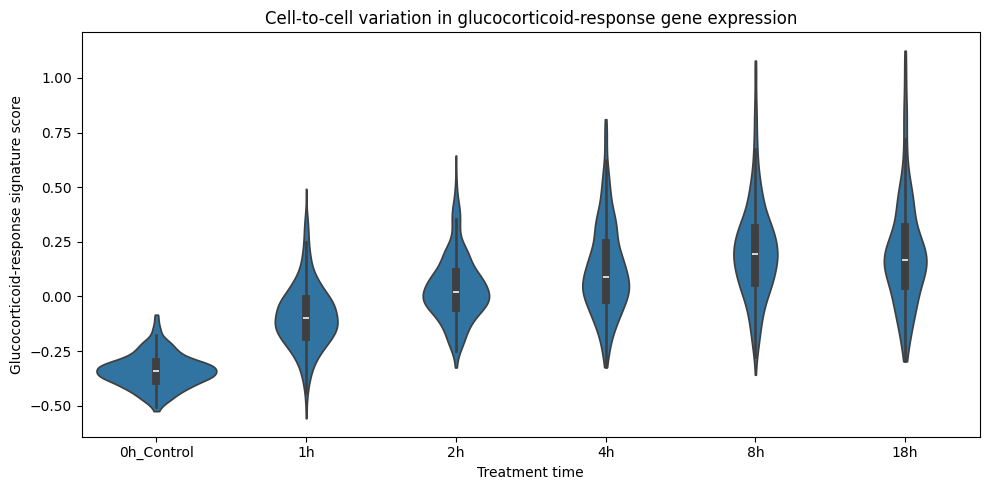

In [ ]:
time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

plot_df = adata.obs[
    ["treatment_time", "GR_response_score"]
].copy()

plot_df["treatment_time"] = pd.Categorical(
    plot_df["treatment_time"],
    categories=time_order,
    ordered=True
)

plt.figure(figsize=(10, 5))

sns.violinplot(
    data=plot_df,
    x="treatment_time",
    y="GR_response_score",
    order=time_order,
    inner="box",
    cut=0
)

plt.xlabel("Treatment time")
plt.ylabel("Glucocorticoid-response signature score")
plt.title("Cell-to-cell variation in glucocorticoid-response gene expression")
plt.tight_layout()
plt.show()

###Examine genes contributing to score variation
Inspects the expression of genes in the response signature to understand which components vary across
cells and time. Because the score is built from these genes, associations between the score and its
component genes are partly expected by construction.

,FKBP5,TSC22D3,NFKBIA,DUSP1,PER1,SGK1,ZBTB16,KLF9,BCL6,CEBPD
treatment_time,,,,,,,,,,
0h_Control,0.691,0.219,0.379,0.014,0.047,0.001,0.011,0.071,0.288,0.178
1h,0.891,0.376,1.314,0.047,0.206,0.057,0.022,0.200,0.770,0.527
2h,1.355,0.510,1.302,0.053,0.383,0.142,0.058,0.262,0.784,0.824
4h,1.972,0.714,1.203,0.114,0.383,0.234,0.138,0.331,0.529,0.957
8h,2.268,0.898,1.167,0.233,0.375,0.236,0.158,0.343,0.700,1.044
18h,2.171,0.962,1.128,0.254,0.346,0.189,0.118,0.365,0.969,0.911


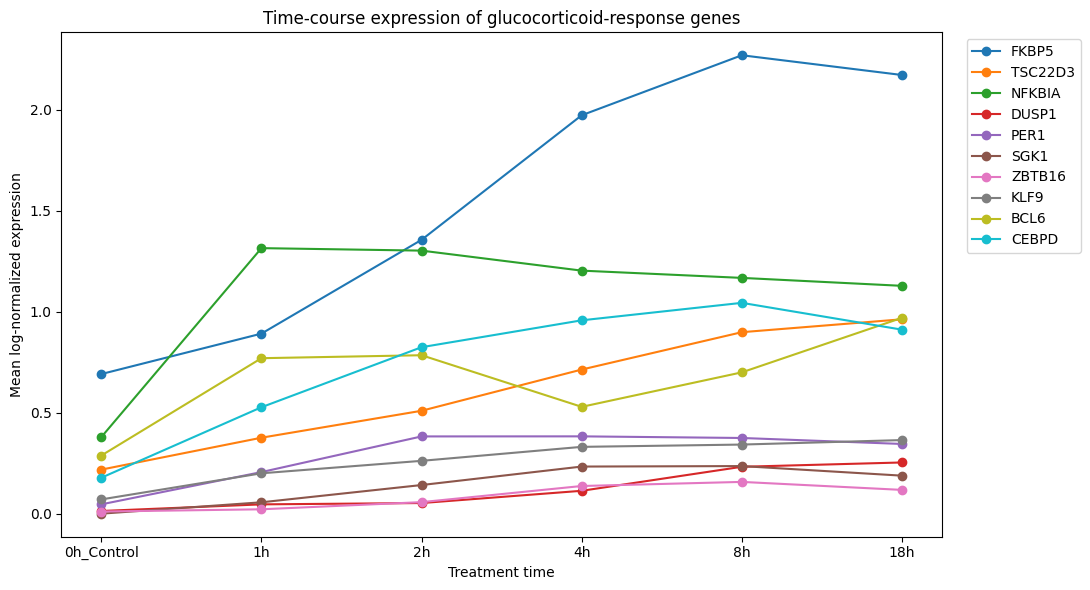

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

signature_genes = [
    "FKBP5", "TSC22D3", "NFKBIA", "DUSP1", "PER1",
    "SGK1", "ZBTB16", "KLF9", "BCL6", "CEBPD"
]

signature_genes = [
    g for g in signature_genes if g in adata.var_names
]

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

# Obtain log-normalized expression for each signature gene
expr = adata[:, signature_genes].to_df()

expr["treatment_time"] = adata.obs["treatment_time"].values

# Summarize each gene at each time point
gene_summary = expr.groupby("treatment_time").agg(
    ["mean", "std"]
)

# Display means in a readable table
gene_means = expr.groupby("treatment_time")[signature_genes].mean()
gene_means = gene_means.reindex(time_order)

display(gene_means.round(3))

# Plot expression trends for the signature genes
plt.figure(figsize=(11, 6))

for gene in signature_genes:
    plt.plot(
        time_order,
        gene_means[gene],
        marker="o",
        label=gene
    )

plt.xlabel("Treatment time")
plt.ylabel("Mean log-normalized expression")
plt.title("Time-course expression of glucocorticoid-response genes")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

###Assess coordinated signature-gene expression
Calculates pairwise or per-gene relationships among signature genes. Correlation can identify co-varying
expression patterns, but it does not establish direct regulatory relationships.

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

signature_genes = [
    "FKBP5", "TSC22D3", "NFKBIA", "DUSP1", "PER1",
    "SGK1", "ZBTB16", "KLF9", "BCL6", "CEBPD"
]

available_genes = [g for g in signature_genes if g in adata.var_names]

# Extract normalized expression and the response score
expr = adata[:, available_genes].to_df()
expr["GR_response_score"] = adata.obs["GR_response_score"].values

# Measure association between each gene and the response score
results = []

for gene in available_genes:
    rho, pval = spearmanr(
        expr[gene],
        expr["GR_response_score"]
    )
    results.append({
        "Gene": gene,
        "Spearman_rho": rho,
        "P_value": pval
    })

correlation_table = pd.DataFrame(results)
correlation_table["FDR"] = (
    correlation_table["P_value"]
    .rank(method="first")
)  # Placeholder; replace below with proper FDR correction

from statsmodels.stats.multitest import multipletests

correlation_table["FDR"] = multipletests(
    correlation_table["P_value"],
    method="fdr_bh"
)[1]

correlation_table = correlation_table.sort_values(
    "Spearman_rho", ascending=False
).reset_index(drop=True)

display(correlation_table.round(4))

,Gene,Spearman_rho,P_value,FDR
0,FKBP5,0.7890,0.0,0.0
1,CEBPD,0.7328,0.0,0.0
2,TSC22D3,0.6708,0.0,0.0
3,NFKBIA,0.6625,0.0,0.0
4,SGK1,0.5192,0.0,0.0
5,KLF9,0.5024,0.0,0.0
6,PER1,0.4895,0.0,0.0
7,DUSP1,0.4812,0.0,0.0
8,BCL6,0.4728,0.0,0.0
9,ZBTB16,0.3778,0.0,0.0


###Test whether score-associated genes vary over time
Quantifies relationships between signature-gene expression and response scores within time groups and
adjusts p-values for multiple comparisons. These are exploratory cell-level associations and require
independent validation.

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

signature_genes = [
    "FKBP5", "TSC22D3", "NFKBIA", "DUSP1", "PER1",
    "SGK1", "ZBTB16", "KLF9", "BCL6", "CEBPD"
]

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

expr = adata[:, signature_genes].to_df()
expr["treatment_time"] = adata.obs["treatment_time"].values
expr["GR_response_score"] = adata.obs["GR_response_score"].values

results = []

for time in time_order:
    subset = expr[expr["treatment_time"] == time]

    for gene in signature_genes:
        rho, pval = spearmanr(
            subset[gene],
            subset["GR_response_score"]
        )

        results.append({
            "Time": time,
            "Gene": gene,
            "Spearman_rho": rho,
            "P_value": pval
        })

correlation_by_time = pd.DataFrame(results)

correlation_by_time["FDR"] = (
    correlation_by_time
    .groupby("Time")["P_value"]
    .transform(lambda p: multipletests(p, method="fdr_bh")[1])
)

# Display each gene's association with the score across time
rho_matrix = correlation_by_time.pivot(
    index="Gene",
    columns="Time",
    values="Spearman_rho"
)[time_order]

display(rho_matrix.round(3))

Time,0h_Control,1h,2h,4h,8h,18h
Gene,,,,,,
BCL6,0.420,0.536,0.408,0.326,0.309,0.509
CEBPD,0.330,0.493,0.498,0.649,0.647,0.652
DUSP1,0.095,0.208,0.151,0.416,0.491,0.534
FKBP5,0.528,0.386,0.502,0.540,0.614,0.708
KLF9,0.263,0.334,0.319,0.401,0.467,0.457
NFKBIA,0.360,0.663,0.641,0.695,0.659,0.742
PER1,0.149,0.210,0.283,0.378,0.359,0.316
SGK1,0.061,0.204,0.381,0.503,0.551,0.401
TSC22D3,0.351,0.432,0.419,0.504,0.591,0.622


###Define high-, intermediate-, and low-score groups
Classifies cells into response-score groups using within-time quantiles. These are analysis-defined
categories, not validated cell types or naturally established responder classes.

In [ ]:
import pandas as pd
import numpy as np

score_df = adata.obs[
    ["treatment_time", "GR_response_score"]
].copy()

score_df["Response_Group"] = "Intermediate"

for time in score_df["treatment_time"].unique():
    mask = score_df["treatment_time"] == time
    scores = score_df.loc[mask, "GR_response_score"]

    low_cutoff = scores.quantile(0.25)
    high_cutoff = scores.quantile(0.75)

    score_df.loc[
        mask & (score_df["GR_response_score"] <= low_cutoff),
        "Response_Group"
    ] = "Low"

    score_df.loc[
        mask & (score_df["GR_response_score"] >= high_cutoff),
        "Response_Group"
    ] = "High"

adata.obs["Response_Group"] = score_df["Response_Group"]

summary = pd.crosstab(
    adata.obs["treatment_time"],
    adata.obs["Response_Group"]
).reindex(
    ["0h_Control", "1h", "2h", "4h", "8h", "18h"]
)

display(summary)

Response_Group,High,Intermediate,Low
treatment_time,,,
0h_Control,100,200,100
1h,100,200,100
2h,100,200,100
4h,100,200,100
8h,100,200,100
18h,100,200,100


###Compare high- and low-score cells
Runs exploratory differential-expression comparisons between high- and low-score cells within each
time point. Since group membership is defined by the score, and the score derives from signature
expression, some associations may be circular or score-dependent.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

response_de = {}

for time in time_order:
    mask = (
        (adata.obs["treatment_time"] == time) &
        (adata.obs["Response_Group"].isin(["High", "Low"]))
    )

    ad = adata[mask].copy()

    sc.tl.rank_genes_groups(
        ad,
        groupby="Response_Group",
        groups=["High"],
        reference="Low",
        method="wilcoxon",
        use_raw=False,
        pts=True
    )

    df = sc.get.rank_genes_groups_df(
        ad,
        group="High"
    )

    df["Time"] = time
    df["Direction"] = np.where(
        df["logfoldchanges"] > 0,
        "Higher in high-score cells",
        "Higher in low-score cells"
    )

    response_de[time] = df

    # Save results
    out = f"/content/glucocorticoid_project/DE_results/High_vs_Low_{time}.csv"
    df.to_csv(out, index=False)

    print(
        f"{time}: "
        f"{(df['pvals_adj'] < 0.05).sum()} genes with FDR < 0.05"
    )

print("Completed. Results saved.")

0h_Control: 8 genes with FDR < 0.05
1h: 119 genes with FDR < 0.05
2h: 61 genes with FDR < 0.05
4h: 546 genes with FDR < 0.05
8h: 321 genes with FDR < 0.05
18h: 507 genes with FDR < 0.05
Completed. Results saved.


### Find genes recurring across time points
Combines high-versus-low comparison results across the six time categories and identifies genes
recurring in multiple comparisons. Recurrence is a candidate-prioritization strategy, not proof of a
reproducible biological effect.

In [ ]:
import pandas as pd
import numpy as np

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

# Combine results from all six time points
combined = pd.concat(
    [response_de[t] for t in time_order],
    ignore_index=True
)

# Keep genes passing the exploratory FDR threshold
significant = combined[combined["pvals_adj"] < 0.05].copy()

# Count recurrence and record direction
recurrence = (
    significant.groupby("names")
    .agg(
        Times_Significant=("Time", "nunique"),
        Significant_Times=("Time", lambda x: ", ".join(
            t for t in time_order if t in set(x)
        )),
        Mean_LogFC=("logfoldchanges", "mean"),
        Min_FDR=("pvals_adj", "min")
    )
    .reset_index()
    .rename(columns={"names": "Gene"})
    .sort_values(
        ["Times_Significant", "Mean_LogFC"],
        ascending=[False, False]
    )
)

# Genes significant in at least 3 time points
recurrent_genes = recurrence[
    recurrence["Times_Significant"] >= 3
]

print("Unique significant genes:", significant["names"].nunique())
print("Genes significant in >=3 time points:", len(recurrent_genes))

display(recurrent_genes.head(30).round(4))

# Save results
recurrence.to_csv(
    "/content/glucocorticoid_project/DE_results/response_gene_recurrence.csv",
    index=False
)

Unique significant genes: 979
Genes significant in >=3 time points: 149


,Gene,Times_Significant,Significant_Times,Mean_LogFC,Min_FDR
145,CEBPD,6,"0h_Control, 1h, 2h, 4h, 8h, 18h",2.1247,0.0000
906,TSC22D3,6,"0h_Control, 1h, 2h, 4h, 8h, 18h",2.0241,0.0000
536,NFKBIA,6,"0h_Control, 1h, 2h, 4h, 8h, 18h",1.8418,0.0000
89,BCL6,6,"0h_Control, 1h, 2h, 4h, 8h, 18h",1.5166,0.0000
299,FKBP5,6,"0h_Control, 1h, 2h, 4h, 8h, 18h",1.2499,0.0000
579,PDK4,5,"1h, 2h, 4h, 8h, 18h",2.7169,0.0000
410,KLF9,5,"1h, 2h, 4h, 8h, 18h",1.9115,0.0000
875,TIPARP,5,"1h, 2h, 4h, 8h, 18h",1.8419,0.0000
966,ZFAND5,5,"1h, 2h, 4h, 8h, 18h",1.1081,0.0000
170,CLPTM1L,5,"1h, 2h, 4h, 8h, 18h",1.1041,0.0000


###Check consistency of effect direction
Checks whether recurring genes change in a consistent direction across treatment-time groups.
Directional consistency helps prioritize candidates, but it does not eliminate pseudoreplication or other
design limitations.

In [ ]:
import pandas as pd
import numpy as np

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

combined = pd.concat(
    [response_de[t] for t in time_order],
    ignore_index=True
)

# Exclude genes used to calculate the response score
signature_genes = {
    "FKBP5", "TSC22D3", "NFKBIA", "DUSP1", "PER1",
    "SGK1", "ZBTB16", "KLF9", "BCL6", "CEBPD"
}

external = combined[~combined["names"].isin(signature_genes)].copy()

external["Significant"] = external["pvals_adj"] < 0.05
external["Direction"] = np.where(
    external["logfoldchanges"] > 0,
    "High",
    "Low"
)

summary = (
    external.groupby("names")
    .agg(
        Times_Significant=("Significant", "sum"),
        Positive_Times=(
            "logfoldchanges",
            lambda x: (x > 0).sum()
        ),
        Negative_Times=(
            "logfoldchanges",
            lambda x: (x < 0).sum()
        ),
        Mean_LogFC=("logfoldchanges", "mean")
    )
    .reset_index()
    .rename(columns={"names": "Gene"})
)

# Retain genes significant in at least 3 time points
# and with a consistent direction across all six time points
consistent = summary[
    (summary["Times_Significant"] >= 3) &
    (
        (summary["Positive_Times"] == 6) |
        (summary["Negative_Times"] == 6)
    )
].sort_values(
    ["Times_Significant", "Mean_LogFC"],
    ascending=[False, False]
)

print("Genes outside the signature meeting these criteria:", len(consistent))
display(consistent.head(30).round(4))

consistent.to_csv(
    "/content/glucocorticoid_project/DE_results/consistent_external_genes.csv",
    index=False
)

Genes outside the signature meeting these criteria: 107


,Gene,Times_Significant,Positive_Times,Negative_Times,Mean_LogFC
29157,TIPARP,5,6,0,1.5931
12403,CLPTM1L,5,6,0,0.9629
17410,IL6ST,5,6,0,0.8722
29699,TPM1,5,6,0,0.8605
24127,RAB11FIP1,5,6,0,0.8302
19743,MAFB,4,6,0,2.0407
18034,KLF15,4,6,0,1.8883
28456,STOM,4,6,0,1.3679
14466,ERRFI1,4,6,0,1.3541
11242,C9orf152,4,6,0,1.0187


###Enrich recurring candidate genes
Runs functional enrichment on the recurring genes associated with higher or lower response scores and
writes results to a response-heterogeneity directory. Treat any enriched terms as exploratory hypotheses.

In [ ]:
import gseapy as gp
import pandas as pd
import os

outdir = "/content/glucocorticoid_project/response_heterogeneity"
os.makedirs(outdir, exist_ok=True)

positive_genes = consistent.loc[
    consistent["Mean_LogFC"] > 0, "Gene"
].astype(str).unique().tolist()

negative_genes = consistent.loc[
    consistent["Mean_LogFC"] < 0, "Gene"
].astype(str).unique().tolist()

enrichment_results = {}

for label, gene_list in [
    ("High_score_associated", positive_genes),
    ("Low_score_associated", negative_genes)
]:
    if len(gene_list) < 5:
        print(f"Skipping {label}: too few genes.")
        continue

    result = gp.enrichr(
        gene_list=gene_list,
        gene_sets=[
            "GO_Biological_Process_2023",
            "KEGG_2021_Human"
        ],
        organism="human",
        outdir=None,
        no_plot=True
    )

    df = result.results.copy()
    enrichment_results[label] = df

    filepath = f"{outdir}/{label}_enrichment.csv"
    df.to_csv(filepath, index=False)

    significant = df[df["Adjusted P-value"] < 0.05]

    print(f"\n{label}: {len(significant)} significant pathways")

    display(
        significant[
            ["Gene_set", "Term", "Adjusted P-value", "Genes"]
        ].head(15)
    )

print(f"\nResults saved in: {outdir}")


High_score_associated: 5 significant pathways


,Gene_set,Term,Adjusted P-value,Genes
0,GO_Biological_Process_2023,Positive Regulation Of ATP-dependent Activity ...,0.012425,VMP1;TPM1;TOR1AIP2;ATP1B1
1,GO_Biological_Process_2023,Negative Regulation Of Cellular Process (GO:00...,0.014184,TSPYL2;CDKN1A;AZGP1;DLG5;TXNIP;NUPR1;RBBP7;JAK...
2,GO_Biological_Process_2023,Regulation Of Keratinocyte Differentiation (GO...,0.031508,ERRFI1;ZFP36;GRHL2
3,GO_Biological_Process_2023,Negative Regulation Of Erythrocyte Differentia...,0.031508,ZFP36;MAFB
915,KEGG_2021_Human,Aldosterone-regulated sodium reabsorption,0.047037,HSD11B2;ATP1A1;ATP1B1



Low_score_associated: 27 significant pathways


,Gene_set,Term,Adjusted P-value,Genes
0,GO_Biological_Process_2023,Aerobic Electron Transport Chain (GO:0019646),0.000013,NDUFB6;NDUFA4;NDUFS6;UQCR10;CYC1
1,GO_Biological_Process_2023,Mitochondrial ATP Synthesis Coupled Electron T...,0.000013,NDUFB6;NDUFA4;NDUFS6;UQCR10;CYC1
2,GO_Biological_Process_2023,Cellular Respiration (GO:0045333),0.000023,NDUFB6;NDUFA4;NDUFS6;UQCR10;CYC1
3,GO_Biological_Process_2023,"Mitochondrial Electron Transport, NADH To Ubiq...",0.001674,NDUFB6;NDUFA4;NDUFS6
4,GO_Biological_Process_2023,Energy Derivation By Oxidation Of Organic Comp...,0.002734,NDUFA4;UQCR10;CYC1
5,GO_Biological_Process_2023,Peptide Biosynthetic Process (GO:0043043),0.005882,RPS15;RPL35;RPL8;MRPL55
6,GO_Biological_Process_2023,Macromolecule Biosynthetic Process (GO:0009059),0.008869,RPS15;RPL35;RPL8;MRPL55
7,GO_Biological_Process_2023,Cytoplasmic Translation (GO:0002181),0.017020,RPS15;RPL35;RPL8
8,GO_Biological_Process_2023,Translation (GO:0006412),0.017544,RPS15;RPL35;RPL8;MRPL55
9,GO_Biological_Process_2023,Protein K11-linked Ubiquitination (GO:0070979),0.030481,UBE2T;ANAPC11



Results saved in: /content/glucocorticoid_project/response_heterogeneity


### Back up the project to Google Drive
Copies or organizes project outputs in the persistent Drive project folder. This is important because the
Colab runtime's local filesystem is temporary.

In [ ]:
# ============================================================
# BACK UP GSE141834 scRNA-seq PROJECT TO GOOGLE DRIVE
# ============================================================

from google.colab import drive
import os
import shutil
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define folders
source_dir = "/content/glucocorticoid_project"

drive_dir = (
    "/content/drive/MyDrive/"
    "GSE141834_Glucocorticoid_scRNAseq_Project"
)

# 3. Confirm that the working project folder exists
if not os.path.exists(source_dir):
    raise FileNotFoundError(
        f"Project folder not found: {source_dir}"
    )

# 4. Create the permanent Drive folder
os.makedirs(drive_dir, exist_ok=True)

# 5. Create a dedicated folder for saved AnnData objects
objects_dir = os.path.join(source_dir, "saved_objects")
os.makedirs(objects_dir, exist_ok=True)

# 6. Save the main AnnData object, if available
if "adata" in globals():
    adata.write_h5ad(
        os.path.join(objects_dir, "adata_full.h5ad")
    )
    print("Saved full AnnData object.")

    # Save cell metadata separately for easy inspection
    adata.obs.to_csv(
        os.path.join(objects_dir, "cell_metadata.csv")
    )

    # Save gene names
    pd.DataFrame({
        "gene": adata.var_names
    }).to_csv(
        os.path.join(objects_dir, "gene_names.csv"),
        index=False
    )
else:
    print("WARNING: adata not found in memory.")

# 7. Save the HVG AnnData object, if available
if "adata_hvg" in globals():
    adata_hvg.write_h5ad(
        os.path.join(objects_dir, "adata_hvg_2000.h5ad")
    )
    print("Saved HVG AnnData object.")
else:
    print("NOTE: adata_hvg not found; skipping.")

# 8. Export the combined response-group DE table, if available
if "combined" in globals() and isinstance(combined, pd.DataFrame):
    combined.to_csv(
        os.path.join(
            source_dir,
            "response_heterogeneity_all_times.csv"
        ),
        index=False
    )
    print("Saved combined response-group results.")

# 9. Export the consistent candidate-gene table, if available
if "consistent" in globals() and isinstance(consistent, pd.DataFrame):
    consistent.to_csv(
        os.path.join(
            source_dir,
            "consistent_external_genes.csv"
        ),
        index=False
    )
    print("Saved consistent candidate genes.")

# 10. Export response-score summaries, if available
if "adata" in globals() and "GR_response_score" in adata.obs.columns:
    score_summary = (
        adata.obs.groupby("treatment_time", observed=True)
        ["GR_response_score"]
        .agg(["count", "mean", "median", "std"])
        .reset_index()
    )

    score_summary.to_csv(
        os.path.join(source_dir, "GR_response_score_summary.csv"),
        index=False
    )
    print("Saved response-score summary.")

# 11. Copy the complete project directory to Google Drive.
# Existing files are updated; unrelated Drive files are preserved.
shutil.copytree(
    source_dir,
    drive_dir,
    dirs_exist_ok=True
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved full AnnData object.
Saved HVG AnnData object.
Saved combined response-group results.
Saved consistent candidate genes.
Saved response-score summary.


'/content/drive/MyDrive/GSE141834_Glucocorticoid_scRNAseq_Project'

### Verify the Drive backup folder
Checks that the expected project folder exists and reports its contents or status. This verifies the backup
location, not necessarily the scientific correctness of every result.

In [ ]:
import os

drive_dir = (
    "/content/drive/MyDrive/"
    "GSE141834_Glucocorticoid_scRNAseq_Project"
)

if not os.path.isdir(drive_dir):
    print("ERROR: Project folder not found in Google Drive.")
else:
    file_count = 0
    total_bytes = 0

    for root, dirs, files in os.walk(drive_dir):
        for filename in files:
            filepath = os.path.join(root, filename)

            if os.path.isfile(filepath):
                file_count += 1
                total_bytes += os.path.getsize(filepath)

    print("=" * 50)
    print("GOOGLE DRIVE BACKUP VERIFICATION")
    print("=" * 50)
    print("Folder:", drive_dir)
    print("Files found:", file_count)
    print(f"Total size: {total_bytes / (1024**3):.2f} GB")
    print("\nTop-level contents:")

    for item in sorted(os.listdir(drive_dir)):
        print(" -", item)

GOOGLE DRIVE BACKUP VERIFICATION
Folder: /content/drive/MyDrive/GSE141834_Glucocorticoid_scRNAseq_Project
Files found: 44
Total size: 0.46 GB

Top-level contents:
 - DE_results
 - GR_response_score_summary.csv
 - GSE141834_scRNAseq_rawCounts.txt.gz
 - consistent_external_genes.csv
 - pathway_enrichment
 - response_heterogeneity
 - response_heterogeneity_all_times.csv
 - saved_objects


###Check required files and reopen saved objects
Verifies key outputs exist and reopens the saved full and HVG AnnData objects to confirm that they can
be read. This is a useful reproducibility check after saving.

In [ ]:
import os
import scanpy as sc

project_dir = (
    "/content/drive/MyDrive/"
    "GSE141834_Glucocorticoid_scRNAseq_Project"
)

# Check important files
required_files = [
    "GSE141834_scRNAseq_rawCounts.txt.gz",
    "GR_response_score_summary.csv",
    "consistent_external_genes.csv",
    "response_heterogeneity_all_times.csv",
    "saved_objects/adata_full.h5ad",
    "saved_objects/adata_hvg_2000.h5ad",
    "saved_objects/cell_metadata.csv",
    "saved_objects/gene_names.csv",
]

print("IMPORTANT FILE CHECK")
missing = []

for name in required_files:
    path = os.path.join(project_dir, name)
    exists = os.path.isfile(path)
    print(f"{'OK' if exists else 'MISSING'}: {name}")
    if not exists:
        missing.append(name)

# Reopen AnnData files to check readability
print("\nANNData READABILITY CHECK")

for name in [
    "saved_objects/adata_full.h5ad",
    "saved_objects/adata_hvg_2000.h5ad",
]:
    path = os.path.join(project_dir, name)

    if os.path.isfile(path):
        try:
            obj = sc.read_h5ad(path, backed="r")
            print(
                f"OK: {name} | "
                f"{obj.n_obs:,} cells × {obj.n_vars:,} genes"
            )
            obj.file.close()
        except Exception as e:
            print(f"ERROR: {name} | {e}")

print("\nFINAL STATUS")
if missing:
    print("Some important files are missing. Review the list above.")
else:
    print("All required files exist. AnnData readability was checked above.")

IMPORTANT FILE CHECK
OK: GSE141834_scRNAseq_rawCounts.txt.gz
OK: GR_response_score_summary.csv
OK: consistent_external_genes.csv
OK: response_heterogeneity_all_times.csv
OK: saved_objects/adata_full.h5ad
OK: saved_objects/adata_hvg_2000.h5ad
OK: saved_objects/cell_metadata.csv
OK: saved_objects/gene_names.csv

ANNData READABILITY CHECK
OK: saved_objects/adata_full.h5ad | 2,400 cells × 32,049 genes
OK: saved_objects/adata_hvg_2000.h5ad | 2,400 cells × 2,000 genes

FINAL STATUS
All required files exist. AnnData readability was checked above.


###Generate final figures and confirm metadata alignment
Creates or saves portfolio figures using the full object's metadata and the HVG object's embedding, with
cell-order alignment checked before combining them. This prevents the earlier class of errors caused by
expecting treatment metadata to exist in the HVG object's obs when it is stored in the full object.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp

project_dir = (
    "/content/drive/MyDrive/"
    "GSE141834_Glucocorticoid_scRNAseq_Project"
)
fig_dir = os.path.join(project_dir, "figures")
os.makedirs(fig_dir, exist_ok=True)

time_order = ["0h_Control", "1h", "2h", "4h", "8h", "18h"]

# --------------------------------------------------
# FIGURE 2: UMAP BY TREATMENT TIME
# Use metadata from adata, coordinates from adata_hvg
# --------------------------------------------------

assert adata.obs_names.equals(adata_hvg.obs_names), (
    "Cell indices differ between adata and adata_hvg. "
    "Stop and align the objects before plotting."
)

coords = adata_hvg.obsm["X_umap"]
times = adata.obs["treatment_time"].astype(str).to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))

for time in time_order:
    mask = times == time
    if mask.any():
        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=10,
            alpha=0.65,
            label=time
        )

ax.set_title("UMAP of Cells by Treatment Time")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.legend(title="Treatment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "02_umap_treatment_time.png"),
            dpi=300, bbox_inches="tight")
plt.close()
print("Saved: 02_umap_treatment_time.png")

# --------------------------------------------------
# FIGURE 3: RESPONSE SCORE OVER TIME
# --------------------------------------------------

plot_df = adata.obs[["treatment_time", "GR_response_score"]].copy()
plot_df["treatment_time"] = pd.Categorical(
    plot_df["treatment_time"],
    categories=time_order,
    ordered=True
)

data = [
    plot_df.loc[
        plot_df["treatment_time"] == time,
        "GR_response_score"
    ].dropna().to_numpy()
    for time in time_order
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data, labels=time_order, showfliers=False)
ax.set_title("Glucocorticoid Response Score Across Time")
ax.set_xlabel("Treatment time")
ax.set_ylabel("Relative response score")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "03_response_score_over_time.png"),
            dpi=300, bbox_inches="tight")
plt.close()
print("Saved: 03_response_score_over_time.png")

# --------------------------------------------------
# FIGURE 4: KEY GENE EXPRESSION
# --------------------------------------------------

genes = ["FKBP5", "TSC22D3", "NFKBIA"]
genes_present = [g for g in genes if g in adata.var_names]

if genes_present:
    fig, axes = plt.subplots(
        1, len(genes_present),
        figsize=(5 * len(genes_present), 4)
    )
    axes = np.atleast_1d(axes)

    for ax, gene in zip(axes, genes_present):
        values = adata[:, gene].X
        if sp.issparse(values):
            values = values.toarray()
        values = np.asarray(values).reshape(-1)

        means = [
            values[times == time].mean()
            if np.any(times == time) else np.nan
            for time in time_order
        ]

        ax.plot(time_order, means, marker="o")
        ax.set_title(gene)
        ax.set_xlabel("Treatment time")
        ax.set_ylabel("Mean log-normalized expression")
        ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, "04_key_gene_expression.png"),
                dpi=300, bbox_inches="tight")
    plt.close()
    print("Saved: 04_key_gene_expression.png")
else:
    print("Key-gene figure skipped: none of the genes were found.")

# --------------------------------------------------
# FIGURE 5: PATHWAY ENRICHMENT
# --------------------------------------------------

enrichment_files = {
    "High response-score-associated": os.path.join(
        project_dir, "response_heterogeneity",
        "High_score_associated_enrichment.csv"
    ),
    "Low response-score-associated": os.path.join(
        project_dir, "response_heterogeneity",
        "Low_score_associated_enrichment.csv"
    ),
}

pathway_frames = []

for group, path in enrichment_files.items():
    if not os.path.isfile(path):
        print("Enrichment file not found:", path)
        continue

    df = pd.read_csv(path)

    p_col = next(
        (c for c in df.columns if c.lower() in
         ["adjusted p-value", "adjusted pvalue", "fdr", "padj"]),
        None
    )
    term_col = next(
        (c for c in df.columns if c.lower() in ["term", "pathway", "name"]),
        None
    )

    if p_col is None or term_col is None:
        print("Could not identify pathway or adjusted P columns:", path)
        print("Available columns:", df.columns.tolist())
        continue

    df[p_col] = pd.to_numeric(df[p_col], errors="coerce")
    df = df.dropna(subset=[p_col])
    df = df[df[p_col] < 0.05].nsmallest(10, p_col).copy()

    if not df.empty:
        df["Group"] = group
        df["TermLabel"] = df[term_col].astype(str)
        df["AdjustedP"] = df[p_col]
        pathway_frames.append(df)

if pathway_frames:
    pathways = pd.concat(pathway_frames, ignore_index=True)
    pathways["-log10 adjusted P"] = -np.log10(
        pathways["AdjustedP"].clip(lower=1e-300)
    )

    pathways = pathways.sort_values("-log10 adjusted P")
    fig, ax = plt.subplots(figsize=(10, 8))

    for group, df in pathways.groupby("Group"):
        ax.scatter(
            df["-log10 adjusted P"],
            df["TermLabel"],
            s=45,
            label=group,
            alpha=0.8
        )

    ax.set_xlabel("-log10(adjusted P-value)")
    ax.set_ylabel("Enriched pathway")
    ax.set_title("Pathway Enrichment of Response-Associated Genes")
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, "05_pathway_enrichment.png"),
                dpi=300, bbox_inches="tight")
    plt.close()
    print("Saved: 05_pathway_enrichment.png")
else:
    print("Pathway figure skipped: no matching significant pathways.")

# --------------------------------------------------
# FINAL FILE LIST
# --------------------------------------------------

print("\nFigures currently saved in Google Drive:")
for filename in sorted(os.listdir(fig_dir)):
    print("-", filename)

Saved: 02_umap_treatment_time.png


/tmp/ipykernel_1449/760142034.py:72: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=time_order, showfliers=False)


Saved: 03_response_score_over_time.png
Saved: 04_key_gene_expression.png
Saved: 05_pathway_enrichment.png

Figures currently saved in Google Drive:
- 01_quality_control.png
- 02_umap_treatment_time.png
- 03_response_score_over_time.png
- 04_key_gene_expression.png
- 05_pathway_enrichment.png
